# Part 1 · Evaluating Gnani Prisma (ASR)

**Goal.** Decide where Prisma is strong and where it breaks before recommending it to a customer.
The customer we have in mind is an Indian contact center (banking, insurance, collections) running
Hindi, Hinglish, regional-language and Indian-English calls over the phone.

**What this notebook does, top to bottom**

1. Defines the test categories and why each one matters.
2. Pulls public audio (FLEURS, GramVaani, MUCS 2021, EdAcc) and creates targeted clips (8 kHz telephony,
   noise at fixed SNRs, long-form, no-speech probes, synthetic banking sentences with numbers).
3. Implements WER and CER from scratch (edit distance with a backtrace for S/D/I counts) and checks them against `jiwer`.
4. Sends every clip to Prisma v3.0 and Prisma v2.5. Responses are cached, so re-running costs no credits.
5. Breaks results down by category and digs into the errors.

Setup: see `README.md`. In short, `pip install -r requirements.txt`, put `GNANI_API_KEY` in `.env`, run all cells.

## 0 · Setup

In [1]:
import os, re, io, csv, json, time, math, base64, hashlib, tarfile, subprocess, unicodedata, warnings
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import requests
import soundfile as sf
from scipy.signal import resample_poly
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

ROOT = Path.cwd()
DATA, RAW = ROOT / "data", ROOT / "data" / "raw"
ASR, AUDIO = DATA / "asr", DATA / "asr" / "audio"
RES = ROOT / "results" / "part1"
FIG = RES / "figures"
for p in (RAW, AUDIO, RES, FIG):
    p.mkdir(parents=True, exist_ok=True)


def load_env(path=ROOT / ".env"):
    """Tiny .env reader so the notebook has no extra dependency."""
    if path.exists():
        for line in path.read_text().splitlines():
            if "=" in line and not line.lstrip().startswith("#"):
                k, v = line.split("=", 1)
                os.environ.setdefault(k.strip(), v.strip())


load_env()
GNANI_API_KEY = os.environ.get("GNANI_API_KEY")
SARVAM_API_KEY = os.environ.get("SARVAM_API_KEY")  # optional, only used to regenerate the synthetic probe clips
assert GNANI_API_KEY, "Put GNANI_API_KEY=... in a .env file next to this notebook"

SEED = 7
SR = 16_000
STT_URL = "https://api.vachana.ai/stt/v3"

# Chart colors: validated categorical slots (blue, orange, aqua) from the dataviz palette.
C_V3, C_V25, C_KT = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "legend.frameon": False,
})


def stable_hash(*parts) -> str:
    return hashlib.sha1("|".join(map(str, parts)).encode()).hexdigest()


def rel(p: Path) -> str:
    return str(Path(p).resolve().relative_to(ROOT.resolve()))

## 1 · Test design

Each category isolates one thing that goes wrong in real Indian calls. Where possible a category reuses
the **same base clips** as the clean set, so the only thing that changes is the condition under test
(paired comparison). The output `format` is chosen to match how each dataset writes its references,
so the score measures recognition rather than formatting conventions.

| # | Category | Why it matters for a contact-center customer | Source | Clips | Prisma `format` |
|---|---|---|---|---|---|
| 1 | `clean_read` (hi, ta) | Best-case baseline. Tamil checks a Dravidian language where CER matters more than WER | FLEURS test (pulled) | 30 hi + 20 ta | `transcribe` (refs use digits) |
| 2 | `telephony_sim` | Same 30 Hindi clips pushed through a phone channel: 300–3400 Hz, 8 kHz, G.711 μ-law | Created from #1 | 30 | `transcribe` |
| 3 | `telephony_real` | Real 8 kHz rural Hindi phone audio with regional accents | GramVaani eval (pulled) | 30 | `verbatim` (refs are spoken form) |
| 4 | `noise_babble` | Call-center chatter at 20, 10, 5, 0 dB SNR. Shows how fast accuracy falls | Created from #1 | 20 × 4 | `transcribe` |
| 5 | `noise_stationary` | Fan / line hiss (pink noise) at 5 dB, to compare against babble at the same SNR | Created from #1 | 20 | `transcribe` |
| 6 | `code_switch` | Hindi-English mixing inside a sentence | MUCS 2021 test (pulled) + clean synthetic Hinglish service lines | 30 + 12 | v3.0 `codemix`, v2.5 `verbatim` |
| 7 | `accent_en` | Indian-accented English, with a small US-English control | EdAcc test (pulled) | 20 + 10 | `verbatim` |
| 8 | `entities` | Amounts in lakh/crore, dates, phone/account numbers, OTPs, EMI/KYC/UPI | Synthetic speech (created) | 24 | `transcribe` |
| 9 | `short_utt` | One- or two-word replies ("हाँ", "नहीं", "जी बोलिए") that drive IVR and agent flows | GramVaani short clips + synthetic | ~20 | `verbatim` |
| 10 | `long_form` | 22–30 s turns (the REST limit is 30 s) | Created by joining FLEURS clips | 10 | `transcribe` |
| 11 | `no_speech` | Silence, hiss, hum, tones, hold music, background babble. Any output is a hallucination | Created | 8 | `verbatim` |

**Models.** Prisma v3.0 (`prisma-v3.0`, newest) and Prisma v2.5 (default). Two extra runs isolate a single variable each:
v3.0 with `keyterms` on the entity set, and v3.0 with `format=verbatim` on the clean set (see 5.7 for why the output format matters).

**Synthetic clips.** The entity and short-utterance probes need sentences that public datasets do not have.
They are generated with an independent TTS (Sarvam Bulbul v3) rather than Gnani's own Timbre, so the vendor's TTS
is not grading its own ASR. The WAVs are saved, so re-running needs no Sarvam key. Synthetic speech is cleaner
than a real caller, so these clips test *formatting and vocabulary*, not acoustic robustness.

## 2 · Data
### 2.1 Download helpers

In [2]:
def download(url: str, dest: Path) -> Path:
    dest = Path(dest)
    if dest.exists() and dest.stat().st_size > 0:
        return dest
    dest.parent.mkdir(parents=True, exist_ok=True)
    tmp = dest.with_name(dest.name + ".part")
    print(f"downloading {url}")
    with requests.get(url, stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(tmp, "wb") as f:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk)
    tmp.rename(dest)
    return dest


def extract_members(tgz: Path, wanted: set, out_dir: Path) -> dict:
    """Stream a .tar.gz once and write only the wanted members (by basename). Returns name -> path."""
    out_dir.mkdir(parents=True, exist_ok=True)
    found = {n: out_dir / n for n in wanted if (out_dir / n).exists()}
    todo = set(wanted) - set(found)
    if not todo:
        return found
    with tarfile.open(tgz, "r|gz") as tf:
        for m in tf:
            name = Path(m.name).name
            if m.isfile() and name in todo:
                (out_dir / name).write_bytes(tf.extractfile(m).read())
                found[name] = out_dir / name
                todo.discard(name)
                if not todo:
                    break
    return found


def read_audio(path_or_bytes, target_sr=SR):
    data, sr = sf.read(io.BytesIO(path_or_bytes) if isinstance(path_or_bytes, bytes) else path_or_bytes,
                       dtype="float32", always_2d=True)
    data = data.mean(axis=1)
    if target_sr and sr != target_sr:
        g = math.gcd(sr, target_sr)
        data = resample_poly(data, target_sr // g, sr // g).astype("float32")
        sr = target_sr
    return data, sr


def write_wav(path: Path, x: np.ndarray, sr: int = SR):
    path.parent.mkdir(parents=True, exist_ok=True)
    peak = float(np.max(np.abs(x))) if len(x) else 0.0
    if peak > 0.99:
        x = x * (0.99 / peak)
    sf.write(path, x, sr, subtype="PCM_16")


MANIFEST_ROWS = []


def add_clip(**kw):
    defaults = dict(subcat="", snr_db=np.nan, noise_type="", base_id="", speaker="", accent="",
                    entities="[]", source="", lang_v3="", fmt_v3="", lang_v25="", fmt_v25="")
    row = {**defaults, **kw}
    info = sf.info(ROOT / row["path"])
    row["duration_s"] = round(info.frames / info.samplerate, 3)
    row["sample_rate"] = info.samplerate
    row["has_digits"] = bool(re.search(r"[0-9०-९]", row["reference"]))
    MANIFEST_ROWS.append(row)


# The repo ships the 336 selected clips and the manifest, so by default section 2 only loads them.
# Set REBUILD = True (or delete data/asr/manifest.csv) to download the public sources (about 1.8 GB)
# and rebuild every clip from scratch with the same seed.
REBUILD = not (ASR / "manifest.csv").exists()
print("Rebuilding the test set from public sources" if REBUILD else "Using the shipped test set in data/asr (REBUILD = False)")

Using the shipped test set in data/asr (REBUILD = False)


### 2.2 Pull: FLEURS Hindi and Tamil (clean read speech)
One recording per sentence, at most 25 s, picked in a fixed hash order so the selection is reproducible.
The Hindi pool is split into disjoint sets: 30 test clips, 6 clips used only to build babble noise,
and 30 clips joined into long-form turns.

In [3]:
if REBUILD:
    FLEURS_URL = "https://huggingface.co/datasets/google/fleurs/resolve/main/data/{lang}/{f}"


    def fleurs_pool(lang: str):
        d = RAW / f"fleurs_{lang}"
        tsv = download(FLEURS_URL.format(lang=lang, f="test.tsv"), d / "test.tsv")
        rows = [dict(fid=r[0], file=r[1], ref=r[3], dur=int(r[5]) / SR, gender=r[6])
                for r in csv.reader(open(tsv, encoding="utf-8"), delimiter="\t", quoting=csv.QUOTE_NONE)]
        best = {}
        for r in rows:  # one recording per sentence id
            if r["dur"] <= 25 and (r["fid"] not in best or stable_hash(r["file"]) < stable_hash(best[r["fid"]]["file"])):
                best[r["fid"]] = r
        return sorted(best.values(), key=lambda r: stable_hash(SEED, r["file"]))


    fl_hi, fl_ta = fleurs_pool("hi_in"), fleurs_pool("ta_in")
    hi_test, hi_babble, hi_long = fl_hi[:30], fl_hi[30:36], fl_hi[36:66]
    ta_test = fl_ta[:20]

    hi_wavs = extract_members(download(FLEURS_URL.format(lang="hi_in", f="audio/test.tar.gz"), RAW / "fleurs_hi_in" / "test.tar.gz"),
                              {r["file"] for r in hi_test + hi_babble + hi_long}, RAW / "fleurs_hi_in" / "wav")
    ta_wavs = extract_members(download(FLEURS_URL.format(lang="ta_in", f="audio/test.tar.gz"), RAW / "fleurs_ta_in" / "test.tar.gz"),
                              {r["file"] for r in ta_test}, RAW / "fleurs_ta_in" / "wav")

    for lang, sel, wavs, code in (("hi", hi_test, hi_wavs, "hi-IN"), ("ta", ta_test, ta_wavs, "ta-IN")):
        for r in sel:
            cid = f"fleurs_{lang}_{Path(r['file']).stem}"
            out = AUDIO / "clean_read" / f"{cid}.wav"
            if not out.exists():
                x, _ = read_audio(wavs[r["file"]])
                write_wav(out, x)
            add_clip(clip_id=cid, category="clean_read", subcat=lang, language=code, path=rel(out), reference=r["ref"],
                     source="FLEURS test", speaker=r["gender"], lang_v3=code, fmt_v3="transcribe", lang_v25=code, fmt_v25="transcribe")
    print(len(MANIFEST_ROWS), "clean clips")

### 2.3 Pull: GramVaani (real 8 kHz rural Hindi telephony)
GramVaani is crowd-sourced phone audio from rural India (OpenSLR 118). The eval split carries accent labels.
Clips between 3 and 29 s go to `telephony_real`. Clips under 2.5 s go to `short_utt`.

In [4]:
if REBUILD:
    GV_URL = "https://openslr.trmal.net/resources/118/GV_Eval_3h.tar.gz"
    gv_dir = RAW / "gramvaani" / "x"
    if not (gv_dir / "GV_Eval_3h" / "text").exists():
        with tarfile.open(download(GV_URL, RAW / "gramvaani" / "GV_Eval_3h.tar.gz")) as tf:
            tf.extractall(gv_dir, filter="data")
    gv_root = gv_dir / "GV_Eval_3h"
    gv_text = dict(l.rstrip("\n").split(" ", 1) for l in open(gv_root / "text", encoding="utf-8") if " " in l.strip())
    gv_lab = pd.read_csv(gv_root / "utt2labels", sep="\t").set_index("Uttids")

    gv_items = []
    for uid, ref in gv_text.items():
        ref = ref.strip()
        if not ref:
            continue
        info = sf.info(gv_root / "Audio" / f"{uid}.mp3")
        gv_items.append(dict(uid=uid, ref=ref, dur=info.frames / info.samplerate))
    gv_items.sort(key=lambda r: stable_hash(SEED, r["uid"]))
    gv_main = [r for r in gv_items if 3 <= r["dur"] <= 29][:30]
    gv_short = [r for r in gv_items if 0.6 <= r["dur"] < 2.5 and len(r["ref"].split()) <= 4][:10]

    for cat, sel in (("telephony_real", gv_main), ("short_utt", gv_short)):
        for r in sel:
            cid = f"gv_{r['uid']}"
            out = AUDIO / cat / f"{cid}.wav"
            if not out.exists():
                x, sr = read_audio(gv_root / "Audio" / f"{r['uid']}.mp3", target_sr=None)  # keep native 8 kHz
                write_wav(out, x, sr)
            lab = gv_lab.loc[r["uid"]] if r["uid"] in gv_lab.index else None
            add_clip(clip_id=cid, category=cat, subcat="gramvaani" if cat == "short_utt" else "rural_hi_8k", language="hi-IN",
                     path=rel(out), reference=r["ref"], source="GramVaani eval",
                     accent="" if lab is None else str(lab["Accent"]), speaker="" if lab is None else str(lab["Gender"]),
                     lang_v3="hi-IN", fmt_v3="verbatim", lang_v25="hi-IN", fmt_v25="verbatim")
    print(len(gv_main), "telephony_real,", len(gv_short), "short GramVaani clips")

### 2.4 Pull: MUCS 2021 Hindi-English code-switched test set
Spoken tutorials where English technical words sit inside Hindi sentences (OpenSLR 104). References keep most
English words in Latin script. One segment per recording, 3 to 25 s, at least one Latin word. Segments with
digits are skipped so number formatting does not get mixed into the code-switching score (numbers get their own category).

In [5]:
if REBUILD:
    MUCS_URL = "https://openslr.trmal.net/resources/104/Hindi-English_test.tar.gz"
    mucs_dir = RAW / "mucs_hien" / "x"
    if not (mucs_dir / "test" / "transcripts" / "text").exists():
        with tarfile.open(download(MUCS_URL, RAW / "mucs_hien" / "Hindi-English_test.tar.gz")) as tf:
            tf.extractall(mucs_dir, filter="data")
    mt = mucs_dir / "test" / "transcripts"
    m_text = dict(l.rstrip("\n").split(" ", 1) for l in open(mt / "text", encoding="utf-8"))
    m_seg = {p[0]: (p[1], float(p[2]), float(p[3])) for p in (l.split() for l in open(mt / "segments"))}

    by_rec = defaultdict(list)
    for uid, (rec, st, en) in m_seg.items():
        ref = m_text.get(uid, "")
        if 3 <= en - st <= 25 and not re.search(r"\d", ref) and re.search(r"[A-Za-z]", ref) and re.search(r"[ऀ-ॿ]", ref):
            by_rec[rec].append((uid, st, en, ref))
    recs = sorted(by_rec, key=lambda r: stable_hash(SEED, r))[:30]
    for rec in recs:
        uid, st, en, ref = min(by_rec[rec], key=lambda t: stable_hash(SEED, t[0]))
        cid = f"mucs_{uid}"
        out = AUDIO / "code_switch" / f"{cid}.wav"
        if not out.exists():
            info = sf.info(mucs_dir / "test" / f"{rec}.wav")
            x, sr = sf.read(mucs_dir / "test" / f"{rec}.wav", start=int(st * info.samplerate), stop=int(en * info.samplerate), dtype="float32", always_2d=True)
            x = x.mean(axis=1)
            if sr != SR:
                g = math.gcd(sr, SR); x = resample_poly(x, SR // g, sr // g).astype("float32")
            write_wav(out, x)
        add_clip(clip_id=cid, category="code_switch", subcat="mucs", language="hi-IN", path=rel(out), reference=ref,
                 source="MUCS 2021 test", speaker=rec, lang_v3="hi-IN,en-IN", fmt_v3="codemix", lang_v25="hi-IN", fmt_v25="verbatim")
    print(len(recs), "code-switch clips")

### 2.5 Pull: EdAcc Indian English (plus a US-English control)
EdAcc is conversational English across accents. Only the parquet row groups that hold the chosen
speakers are read, so the download stays small. Fillers (`UM`, `UH`) are removed during normalization.

In [6]:
if REBUILD:
    def edacc_select():
        import pyarrow.parquet as pq
        from huggingface_hub import HfFileSystem
        fs = HfFileSystem()
        plan = {  # speaker -> (accent group, how many)
            "EDACC-C36-A": ("indian", 8), "EDACC-C05-B": ("indian", 8), "EDACC-C34-A": ("indian", 4),
            "EDACC-C63-B": ("us", 5), "EDACC-C64-A": ("us", 5),
        }
        picked = []
        for f in sorted(fs.glob("datasets/edinburghcstr/edacc/data/test-*.parquet")):
            pf = pq.ParquetFile(fs.open(f))
            meta = pf.read(columns=["speaker", "accent", "l1", "text"]).to_pylist()
            rows = [(i, m) for i, m in enumerate(meta) if m["speaker"] in plan and "IGNORE" not in m["text"]
                    and 6 <= len(m["text"].split()) <= 45]
            if not rows:
                continue
            bounds = np.cumsum([0] + [pf.metadata.row_group(g).num_rows for g in range(pf.num_row_groups)])
            need = defaultdict(list)
            for spk in {m["speaker"] for _, m in rows}:
                cand = sorted([(i, m) for i, m in rows if m["speaker"] == spk], key=lambda t: stable_hash(SEED, f, t[0]))
                for i, m in cand[: plan[spk][1] * 2]:  # read extra in case some are too long
                    need[int(np.searchsorted(bounds, i, side="right") - 1)].append((i, m))
            for g, items in need.items():
                tbl = pf.read_row_group(g, columns=["audio"]).column("audio").to_pylist()
                for i, m in items:
                    x, _ = read_audio(tbl[i - bounds[g]]["bytes"])
                    picked.append(dict(idx=f"{Path(f).stem[:10]}_{i}", x=x, **m))
        out = []
        for spk, (grp, n) in plan.items():
            cand = [p for p in picked if p["speaker"] == spk and 1.5 <= len(p["x"]) / SR <= 28]
            cand.sort(key=lambda p: stable_hash(SEED, p["idx"]))
            out += [dict(p, group=grp) for p in cand[:n]]
        return out


    if not list((AUDIO / "accent_en").glob("*.wav")):
        for p in edacc_select():
            write_wav(AUDIO / "accent_en" / f"edacc_{p['group']}_{p['speaker']}_{p['idx']}.wav", p["x"])
            (AUDIO / "accent_en" / f"edacc_{p['group']}_{p['speaker']}_{p['idx']}.json").write_text(
                json.dumps(dict(text=p["text"], accent=p["accent"], l1=p["l1"], speaker=p["speaker"], group=p["group"])))
    for js in sorted((AUDIO / "accent_en").glob("*.json")):
        m = json.loads(js.read_text())
        add_clip(clip_id=js.stem, category="accent_en", subcat=m["group"], language="en-IN", path=rel(js.with_suffix(".wav")),
                 reference=m["text"], source="EdAcc test", speaker=m["speaker"], accent=f"{m['accent']} (L1 {m['l1']})",
                 lang_v3="en-IN", fmt_v3="verbatim", lang_v25="en-IN", fmt_v25="verbatim")
    print(sum(r["category"] == "accent_en" for r in MANIFEST_ROWS), "accent clips")

### 2.6 Create: telephony channel, noise ladder, long-form turns, no-speech probes

* **Telephony.** Band-pass 300–3400 Hz, resample to 8 kHz, encode and decode G.711 μ-law with ffmpeg. The 8 kHz file is sent as is.
* **SNR.** Signal power is measured on active speech only (20 ms frames within 30 dB of the loudest frame),
  so leading and trailing silence does not inflate the real SNR.
* **Babble** is six overlapping FLEURS speakers that are not in the test set. **Pink noise** is generated with a 1/f spectrum.

In [7]:
if REBUILD:
    rng = np.random.default_rng(SEED)


    def active_power(x, sr=SR, frame=0.02, floor_db=30):
        n = int(sr * frame)
        fr = x[: len(x) // n * n].reshape(-1, n)
        p = (fr ** 2).mean(axis=1) + 1e-12
        keep = p >= p.max() * 10 ** (-floor_db / 10)
        return float(p[keep].mean())


    def mix_at_snr(speech, noise, snr_db):
        if len(noise) < len(speech):
            noise = np.tile(noise, int(np.ceil(len(speech) / len(noise))))
        off = int(rng.integers(0, len(noise) - len(speech) + 1))
        nz = noise[off: off + len(speech)]
        scale = np.sqrt(active_power(speech) / (10 ** (snr_db / 10)) / ((nz ** 2).mean() + 1e-12))
        return speech + scale * nz


    def pink_noise(n):
        spec = np.fft.rfft(rng.standard_normal(n))
        f = np.fft.rfftfreq(n, 1 / SR); f[0] = f[1]
        y = np.fft.irfft(spec / np.sqrt(f), n)
        return (y / np.std(y)).astype("float32")


    def phone_channel(src: Path, dst: Path):
        """300-3400 Hz band-pass -> 8 kHz -> G.711 mu-law -> decode back to 16-bit PCM at 8 kHz."""
        dst.parent.mkdir(parents=True, exist_ok=True)
        tmp = dst.with_name(dst.stem + "_ulaw.wav")
        subprocess.run(["ffmpeg", "-loglevel", "error", "-y", "-i", str(src), "-af", "highpass=f=300,lowpass=f=3400",
                        "-ar", "8000", "-ac", "1", "-c:a", "pcm_mulaw", str(tmp)], check=True)
        subprocess.run(["ffmpeg", "-loglevel", "error", "-y", "-i", str(tmp), "-c:a", "pcm_s16le", str(dst)], check=True)
        tmp.unlink()


    # babble bed from 6 held-out speakers
    bab = [read_audio(hi_wavs[r["file"]])[0] for r in hi_babble]
    L = max(map(len, bab))
    babble = sum(np.pad(b / (np.std(b) + 1e-9), (0, L - len(b)), mode="wrap") for b in bab).astype("float32")
    babble /= np.std(babble)

    clean_hi = [r for r in MANIFEST_ROWS if r["category"] == "clean_read" and r["subcat"] == "hi"]
    for r in clean_hi:  # telephony_sim: all 30
        out = AUDIO / "telephony_sim" / f"{r['clip_id']}_g711.wav"
        if not out.exists():
            phone_channel(ROOT / r["path"], out)
        add_clip(**{**{k: r[k] for k in ("reference", "language", "lang_v3", "fmt_v3", "lang_v25", "fmt_v25", "speaker")},
                    "clip_id": out.stem, "category": "telephony_sim", "subcat": "g711_8k", "path": rel(out),
                    "source": "FLEURS test + simulated phone channel", "base_id": r["clip_id"]})

    for r in clean_hi[:20]:  # noise ladder on the first 20
        x, _ = read_audio(ROOT / r["path"])
        for ntype, snrs in (("babble", (20, 10, 5, 0)), ("pink", (5,))):
            for snr in snrs:
                cat = "noise_babble" if ntype == "babble" else "noise_stationary"
                out = AUDIO / cat / f"{r['clip_id']}_{ntype}{snr}dB.wav"
                if not out.exists():
                    write_wav(out, mix_at_snr(x, babble if ntype == "babble" else pink_noise(len(x) + SR), snr))
                add_clip(**{**{k: r[k] for k in ("reference", "language", "lang_v3", "fmt_v3", "lang_v25", "fmt_v25", "speaker")},
                            "clip_id": out.stem, "category": cat, "subcat": f"{ntype}_{snr}dB", "path": rel(out),
                            "snr_db": snr, "noise_type": ntype, "source": "FLEURS test + created noise", "base_id": r["clip_id"]})

    # long-form: join FLEURS clips (separate pool) until the turn is 22-29.5 s
    gap = np.zeros(int(0.4 * SR), dtype="float32")
    pool = list(hi_long)
    k = 0
    while pool and k < 10:
        parts, refs, total = [], [], 0.0
        for r in list(pool):
            if total + r["dur"] + 0.4 <= 29.5:
                parts.append(read_audio(hi_wavs[r["file"]])[0]); refs.append(r["ref"]); total += r["dur"] + 0.4
                pool.remove(r)
            if total >= 22:
                break
        if total < 22:
            break
        out = AUDIO / "long_form" / f"fleurs_hi_long_{k:02d}.wav"
        if not out.exists():
            write_wav(out, np.concatenate([np.concatenate([p, gap]) for p in parts]))
        add_clip(clip_id=out.stem, category="long_form", subcat="22-30s", language="hi-IN", path=rel(out), reference=" ".join(refs),
                 source="FLEURS test (joined)", lang_v3="hi-IN", fmt_v3="transcribe", lang_v25="hi-IN", fmt_v25="transcribe")
        k += 1

    # no-speech probes: the right answer is an empty transcript
    t = np.arange(5 * SR) / SR
    tone = lambda f: np.sin(2 * np.pi * f * t)
    NO_SPEECH = {
        "silence": np.zeros_like(t),
        "white_noise_-45dBFS": rng.standard_normal(len(t)) * 10 ** (-45 / 20),
        "pink_noise_-30dBFS": pink_noise(len(t)) * 10 ** (-30 / 20),
        "mains_hum_50Hz": 0.05 * (tone(50) + 0.5 * tone(100) + 0.3 * tone(150)),
        "ringback_tone": 0.2 * (tone(400) * (1 + 0.5 * tone(25))) * ((t % 3) < 1.0),
        "hold_music": 0.15 * sum(np.sin(2 * np.pi * f * t) * ((t // 0.5 % 4) == i) for i, f in enumerate((262, 330, 392, 523))),
        "babble_only_-25dBFS": babble[: len(t)] * 10 ** (-25 / 20),
        "keyboard_clicks": np.convolve((rng.random(len(t)) < 0.0008).astype(float) * 0.6, np.hanning(60), mode="same"),
    }
    for name, x in NO_SPEECH.items():
        out = AUDIO / "no_speech" / f"nospeech_{name}.wav"
        if not out.exists():
            write_wav(out, x.astype("float32"))
        add_clip(clip_id=out.stem, category="no_speech", subcat=name, language="hi-IN", path=rel(out), reference="",
                 source="created", lang_v3="hi-IN", fmt_v3="verbatim", lang_v25="hi-IN", fmt_v25="verbatim")
    print(len(MANIFEST_ROWS), "clips so far")

### 2.7 Create: synthetic banking sentences and short replies

Each entity sentence lists the entities a downstream system would actually need. An entity counts as correct
only if one of its accepted written forms appears in Prisma's output. Numbers must come back as digits,
because that is what `format=transcribe` (inverse text normalization) promises.

In [8]:
if REBUILD:
    E = lambda *forms: list(forms)
    PROBES = [
        # Hindi
        ("ent_hi_01", "hi", "आपकी EMI ₹12,500 है, जो 5 दिसंबर तक जमा करनी है।", [E("emi", "ईएमआई", "ई एम आई"), E("12500"), E("5 दिसंबर", "5 december")]),
        ("ent_hi_02", "hi", "आपके लोन खाते में ₹2,35,000 बकाया है।", [E("235000"), E("लोन", "loan")]),
        ("ent_hi_03", "hi", "कृपया अपना छह अंकों का OTP 482917 बताइए।", [E("482917"), E("otp", "ओटीपी", "ओ टी पी")]),
        ("ent_hi_04", "hi", "मेरा मोबाइल नंबर 9876543210 है।", [E("9876543210")]),
        ("ent_hi_05", "hi", "पॉलिसी का प्रीमियम ₹18,750 सालाना है और अगली तारीख 15 जनवरी 2027 है।", [E("18750"), E("15 जनवरी 2027", "15 january 2027"), E("प्रीमियम", "premium")]),
        ("ent_hi_06", "hi", "आपका KYC अपडेट नहीं हुआ है, कृपया नज़दीकी शाखा जाएँ।", [E("kyc", "केवाईसी", "के वाई सी")]),
        ("ent_hi_07", "hi", "UPI से ₹499 का भुगतान सफल रहा।", [E("upi", "यूपीआई", "यू पी आई"), E("499")]),
        ("ent_hi_08", "hi", "होम लोन पर ब्याज दर 8.5 प्रतिशत सालाना है।", [E("8.5"), E("होम लोन", "home loan")]),
        ("ent_hi_09", "hi", "आपका खाता संख्या 50100234567 है।", [E("50100234567")]),
        ("ent_hi_10", "hi", "कल शाम 4:30 बजे हमारे एजेंट आपको कॉल करेंगे।", [E("4:30", "04:30", "16:30")]),
        ("ent_hi_11", "hi", "आपके क्रेडिट कार्ड की बकाया राशि ₹1,25,000 है।", [E("125000"), E("क्रेडिट कार्ड", "credit card")]),
        ("ent_hi_12", "hi", "पिन कोड 560034 वाले ग्राहकों के लिए नई शाखा खुली है।", [E("560034")]),
        # Indian English
        ("ent_en_01", "en", "Your EMI of ₹15,000 is due on 7th December.", [E("emi"), E("15000"), E("7th december", "7 december", "december 7")]),
        ("ent_en_02", "en", "Please share the IFSC code HDFC0001234 for the NEFT transfer.", [E("hdfc0001234", "hdfc 0001234"), E("neft")]),
        ("ent_en_03", "en", "Your CIBIL score is 742.", [E("cibil"), E("742")]),
        ("ent_en_04", "en", "The policy number is 4520 3398 1176.", [E("452033981176")]),
        ("ent_en_05", "en", "We have received a payment of ₹2,50,000 on 3rd March 2026.", [E("250000"), E("3rd march 2026", "3 march 2026", "march 3 2026")]),
        ("ent_en_06", "en", "Call our toll-free number 1800 266 1234 for help.", [E("18002661234")]),
        # Hinglish (English words kept in Latin, as people type them)
        ("ent_cm_01", "cm", "सर, आपका payment pending है, please आज ही pay कर दीजिए।", [E("payment", "पेमेंट"), E("pending", "पेंडिंग")]),
        ("ent_cm_02", "cm", "मैंने already ₹5,000 transfer कर दिए हैं, आप check कर लीजिए।", [E("5000"), E("transfer", "ट्रांसफर")]),
        ("ent_cm_03", "cm", "आपका loan approval process में है, 2 working days लगेंगे।", [E("loan", "लोन"), E("approval", "अप्रूवल"), E("2")]),
        ("ent_cm_04", "cm", "Credit card का bill ₹8,240 है, due date 20 November है।", [E("8240"), E("20 november", "20 नवंबर")]),
        ("ent_cm_05", "cm", "मुझे अपना account statement email पर चाहिए।", [E("account statement", "अकाउंट स्टेटमेंट"), E("email", "ईमेल")]),
        ("ent_cm_06", "cm", "आपकी policy renew करने के लिए premium ₹6,999 pay करना होगा।", [E("6999"), E("premium", "प्रीमियम"), E("policy", "पॉलिसी")]),
    ]
    # Clean Hinglish customer-service lines (no digits). They complement MUCS, whose subtitle-based timestamps
    # and references are noisy (see 5.7).
    CODESWITCH = [
        ("cs_01", "मेरा account block हो गया है, please इसे unblock कर दीजिए।"),
        ("cs_02", "आपकी request हमने register कर ली है, जल्दी ही update मिलेगा।"),
        ("cs_03", "Sir, आपका card delivery के लिए dispatch हो चुका है।"),
        ("cs_04", "मुझे अपनी policy cancel करनी है, process क्या है?"),
        ("cs_05", "Network issue की वजह से call drop हो गया था।"),
        ("cs_06", "आप app में login करके password reset कर सकते हैं।"),
        ("cs_07", "मेरी complaint का status अभी भी pending दिखा रहा है।"),
        ("cs_08", "Branch manager से बात करवा दीजिए, यह urgent है।"),
        ("cs_09", "आपका refund initiate हो गया है, bank account में credit हो जाएगा।"),
        ("cs_10", "Delivery address change करना है, क्या यह possible है?"),
        ("cs_11", "हमारी team आपको callback करेगी, please available रहिए।"),
        ("cs_12", "Insurance claim के लिए सारे documents upload कर दीजिए।"),
    ]
    SHORT = [("short_01", "hi", "हाँ"), ("short_02", "hi", "नहीं"), ("short_03", "hi", "हाँ जी"), ("short_04", "hi", "जी बोलिए"),
             ("short_05", "hi", "ठीक है"), ("short_06", "hi", "नहीं चाहिए"), ("short_07", "hi", "बाद में कॉल कीजिए"),
             ("short_08", "hi", "हेलो"), ("short_09", "en", "Yes."), ("short_10", "en", "Wrong number.")]
    VOICES = ["shubh", "priya", "rahul", "simran"]
    LANG = {"hi": ("hi-IN", "hi-IN", "hi-IN"), "en": ("en-IN", "en-IN", "en-IN"), "cm": ("hi-IN", "hi-IN,en-IN", "hi-IN")}
    # (TTS language, v3.0 language_code, v2.5 language_code)


    def sarvam_tts(text, lang, speaker, out: Path):
        if out.exists():
            return
        assert SARVAM_API_KEY, f"{out.name} missing and no SARVAM_API_KEY to regenerate it"
        r = requests.post("https://api.sarvam.ai/text-to-speech", headers={"api-subscription-key": SARVAM_API_KEY},
                          json={"text": text, "target_language_code": lang, "speaker": speaker, "model": "bulbul:v3",
                                "speech_sample_rate": SR}, timeout=60)
        r.raise_for_status()
        x, sr = read_audio(base64.b64decode(r.json()["audios"][0]))
        write_wav(out, x, sr)


    for i, (cid, lg, text, ents) in enumerate(PROBES):
        tts_lang, l3, l25 = LANG[lg]
        out = AUDIO / "entities" / f"{cid}.wav"
        sarvam_tts(text, tts_lang, VOICES[i % 4], out)
        add_clip(clip_id=cid, category="entities", subcat={"hi": "hindi", "en": "english", "cm": "hinglish"}[lg], language=tts_lang,
                 path=rel(out), reference=text, entities=json.dumps(ents, ensure_ascii=False), speaker=VOICES[i % 4],
                 source="synthetic (Sarvam Bulbul v3)", lang_v3=l3, fmt_v3="transcribe", lang_v25=l25, fmt_v25="transcribe")
    for i, (cid, text) in enumerate(CODESWITCH):
        out = AUDIO / "code_switch" / f"{cid}.wav"
        sarvam_tts(text, "hi-IN", VOICES[(i + 1) % 4], out)
        add_clip(clip_id=cid, category="code_switch", subcat="synthetic", language="hi-IN", path=rel(out), reference=text,
                 speaker=VOICES[(i + 1) % 4], source="synthetic (Sarvam Bulbul v3)",
                 lang_v3="hi-IN,en-IN", fmt_v3="codemix", lang_v25="hi-IN", fmt_v25="verbatim")
    for i, (cid, lg, text) in enumerate(SHORT):
        tts_lang, l3, l25 = LANG[lg]
        out = AUDIO / "short_utt" / f"{cid}.wav"
        sarvam_tts(text, tts_lang, VOICES[i % 4], out)
        add_clip(clip_id=cid, category="short_utt", subcat="synthetic", language=tts_lang, path=rel(out), reference=text,
                 speaker=VOICES[i % 4], source="synthetic (Sarvam Bulbul v3)", lang_v3=l3, fmt_v3="verbatim", lang_v25=l25, fmt_v25="verbatim")

    manifest = pd.DataFrame(MANIFEST_ROWS)
    assert manifest.clip_id.is_unique and (manifest.duration_s <= 30).all()
    manifest.to_csv(ASR / "manifest.csv", index=False)
    pd.DataFrame([dict(clip_id=c, lang=l, text=t, entities=json.dumps(e, ensure_ascii=False)) for c, l, t, e in PROBES]
                 ).to_csv(ASR / "entity_probes.csv", index=False)

# Both paths load the manifest from disk, so they behave identically.
manifest = pd.read_csv(ASR / "manifest.csv", keep_default_na=False)
manifest["snr_db"] = pd.to_numeric(manifest.snr_db, errors="coerce")
manifest["has_digits"] = manifest.has_digits.astype(str).eq("True")
missing = [p for p in manifest.path if not (ROOT / p).exists()]
assert not missing, f"{len(missing)} clips are missing: set REBUILD = True to rebuild them"

### 2.8 Test set overview

In [9]:
overview = (manifest.groupby("category", sort=False)
            .agg(clips=("clip_id", "size"), minutes=("duration_s", lambda s: round(s.sum() / 60, 1)),
                 median_s=("duration_s", "median"), sample_rates=("sample_rate", lambda s: sorted(set(s))),
                 source=("source", "first")))
print(f"{len(manifest)} clips, {manifest.duration_s.sum() / 60:.1f} minutes of audio")
overview

336 clips, 56.9 minutes of audio


,clips,minutes,median_s,sample_rates,source
category,,,,,
clean_read,50,10.2,11.8200,[16000],FLEURS test
telephony_real,30,4.6,9.6200,"[8000, 16000, 44100, 48000]",GramVaani eval
short_utt,14,0.3,1.1215,"[8000, 16000, 44100]",GramVaani eval
code_switch,42,4.3,4.8040,[16000],MUCS 2021 test
accent_en,28,3.3,5.6800,[16000],EdAcc test
telephony_sim,30,6.3,12.1500,[8000],FLEURS test + simulated phone channel
noise_babble,80,16.9,12.3000,[16000],FLEURS test + created noise
noise_stationary,20,4.2,12.3000,[16000],FLEURS test + created noise
long_form,10,4.4,27.4000,[16000],FLEURS test (joined)


## 3 · Metrics, implemented from scratch

**WER** = (S + D + I) / N over words. **CER** is the same over characters (Unicode code points after NFC,
single spaces included, which matches `jiwer`). The edit distance is a standard dynamic program, and a
backtrace splits the edits into substitutions, deletions and insertions.

**Aggregate WER** is corpus-level: total edits divided by total reference words. A plain mean of per-clip
WER over-weights very short clips. Both are reported, with a bootstrap 95% interval on the corpus value.

**Normalization** (applied to reference and hypothesis alike):
NFC → lowercase → drop tags like `<laugh>` → remove digit-group commas (`8,00,000` → `800000`) →
keep decimal points → strip punctuation and symbols, including the danda `।` and `₹` → drop zero-width joiners →
drop English fillers (um, uh, hmm) → collapse spaces.

A **lenient** variant also folds two spelling choices that native readers treat as the same word:
nukta (`ज़` = `ज`) and chandrabindu vs anusvara (`हाँ` = `हां`). It is reported next to the standard score to show how much
"error" is only spelling convention. The standard score stays the headline.

In [10]:
FILLERS = {"um", "umm", "uh", "uhh", "uhm", "hmm", "hm", "mm", "mhm", "er", "erm", "ah", "eh", "हम्म", "उम्म"}


def normalize(text: str, lenient: bool = False) -> str:
    t = unicodedata.normalize("NFC", str(text or "")).lower()
    t = re.sub(r"<[^>]*>|\[[^\]]*\]", " ", t)
    t = re.sub(r"(?<=\d)[,](?=\d)", "", t)
    t = re.sub(r"(?<=\d)\.(?=\d)", "", t)            # protect decimals
    t = re.sub(r"(?<=\w)['’](?=\w)", "", t)                # i'm -> im
    t = t.replace("‌", "").replace("‍", "")
    t = "".join(" " if unicodedata.category(c)[0] in "PSZ" else c for c in t)
    t = t.replace("", ".")
    if lenient:
        t = t.replace("़", "").replace("ँ", "ं")
    return " ".join(w for w in t.split() if w not in FILLERS)


def align(ref, hyp):
    """Levenshtein alignment. Returns (S, D, I, ops) where ops lists ('C'|'S'|'D'|'I', ref_tok, hyp_tok)."""
    n, m = len(ref), len(hyp)
    prev = list(range(m + 1))
    D = [prev]
    for i in range(1, n + 1):
        cur = [i] + [0] * m
        ri = ref[i - 1]
        for j in range(1, m + 1):
            cur[j] = min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ri != hyp[j - 1]))
        D.append(cur)
        prev = cur
    i, j, S, Dl, I, ops = n, m, 0, 0, 0, []
    while i > 0 or j > 0:
        if i > 0 and j > 0 and D[i][j] == D[i - 1][j - 1] + (ref[i - 1] != hyp[j - 1]):
            if ref[i - 1] != hyp[j - 1]:
                S += 1; ops.append(("S", ref[i - 1], hyp[j - 1]))
            else:
                ops.append(("C", ref[i - 1], hyp[j - 1]))
            i, j = i - 1, j - 1
        elif i > 0 and D[i][j] == D[i - 1][j] + 1:
            Dl += 1; ops.append(("D", ref[i - 1], None)); i -= 1
        else:
            I += 1; ops.append(("I", None, hyp[j - 1])); j -= 1
    return S, Dl, I, ops[::-1]


def score(ref: str, hyp: str, lenient=False) -> dict:
    r, h = normalize(ref, lenient), normalize(hyp, lenient)
    rw, hw = r.split(), h.split()
    S, Dl, I, ops = align(rw, hw)
    cS, cD, cI, _ = align(list(r), list(h))
    return dict(N=len(rw), S=S, D=Dl, I=I, edits=S + Dl + I, wer=(S + Dl + I) / len(rw) if rw else np.nan,
                Nc=len(r), cedits=cS + cD + cI, cer=(cS + cD + cI) / len(r) if r else np.nan,
                hyp_words=len(hw), ops=ops)


# quick unit tests
assert score("a b c d", "a x c d e")[ "edits"] == 2 and score("a b c d", "a x c d e")["S"] == 1
assert normalize("₹8,00,000 का लोन।") == "800000 का लोन" and normalize("8.5 प्रतिशत") == "8.5 प्रतिशत"
assert normalize("हाँ, ज़रूर", lenient=True) == "हां जरूर"
assert normalize("UM I'M fine <laugh>") == "im fine"
print("metric unit tests pass")

metric unit tests pass


## 4 · Run Prisma

Each request is sent once and cached in `results/part1/responses.jsonl`. The account allows one active
request at a time (a second parallel call returns HTTP 429), so calls run sequentially with backoff.
Latency fields from the API: `processing_time` (server compute) and `end_to_end_latency` (includes upload).
Client wall time is also logged, but it depends on where this notebook runs, so it is not used to judge the model.

In [11]:
KEYTERMS = ["EMI", "KYC", "UPI", "OTP", "NEFT", "IFSC", "CIBIL", "HDFC", "प्रीमियम", "पॉलिसी", "लोन", "ब्याज"]
RUNS = {
    "prisma-v3.0": dict(model="prisma-v3.0", lang="lang_v3", fmt="fmt_v3", cats=None, extra={}),
    "prisma-v2.5": dict(model=None, lang="lang_v25", fmt="fmt_v25", cats=None, extra={}),
    "prisma-v3.0+keyterms": dict(model="prisma-v3.0", lang="lang_v3", fmt="fmt_v3", cats={"entities"},
                                 extra={"keyterms": json.dumps(KEYTERMS, ensure_ascii=False)}),
    # Ablation: v3.0 `transcribe` keeps English loanwords in Latin, FLEURS writes them in Devanagari.
    # `verbatim` writes them in native script (but spells numbers out). Run both on the clean set.
    "prisma-v3.0 verbatim": dict(model="prisma-v3.0", lang="lang_v3", fmt=None, fmt_fixed="verbatim",
                                 cats={"clean_read", "telephony_sim", "noise_babble", "noise_stationary", "long_form"}, extra={}),
}
RUN_ORDER = ["prisma-v3.0", "prisma-v3.0 verbatim", "prisma-v2.5"]
RUN_COLOR = {"prisma-v3.0": C_V3, "prisma-v3.0 verbatim": C_KT, "prisma-v2.5": C_V25}
CACHE = RES / "responses.jsonl"


def load_cache():
    c = {}
    if CACHE.exists():
        for line in CACHE.read_text(encoding="utf-8").splitlines():
            d = json.loads(line)
            if d["status"] == 200:
                c[(d["run"], d["clip_id"])] = d
    return c


def transcribe(path: Path, data: dict, max_tries=8):
    wait = 1.0
    for attempt in range(max_tries):
        t0 = time.time()
        try:
            with open(path, "rb") as f:
                r = requests.post(STT_URL, headers={"X-API-Key-ID": GNANI_API_KEY},
                                  files={"audio_file": (path.name, f, "audio/wav")}, data=data, timeout=90)
        except requests.RequestException as e:
            status, body = -1, {"error": str(e)}
        else:
            status = r.status_code
            try:
                body = r.json()
            except ValueError:
                body = {"raw": r.text[:500]}
        wall = time.time() - t0
        if status == 200 or status in (400, 401, 402, 403, 422):
            return status, body, wall
        time.sleep(wait); wait = min(wait * 2, 20)   # 429 / 5xx / network: back off and retry
    return status, body, wall


cache = load_cache()
todo = [(run, row) for run, cfg in RUNS.items() for row in manifest.itertuples()
        if (cfg["cats"] is None or row.category in cfg["cats"]) and (run, row.clip_id) not in cache]
print(f"{len(cache)} cached responses, {len(todo)} requests to send")
with open(CACHE, "a", encoding="utf-8") as fh:
    for n, (run, row) in enumerate(todo, 1):
        cfg = RUNS[run]
        data = {"language_code": getattr(row, cfg["lang"]),
                "format": cfg.get("fmt_fixed") or getattr(row, cfg["fmt"]), **cfg["extra"]}
        if cfg["model"]:
            data["model"] = cfg["model"]
        status, body, wall = transcribe(ROOT / row.path, data)
        rec = dict(run=run, clip_id=row.clip_id, request=data, status=status, body=body, client_wall_s=round(wall, 3),
                   ts=time.strftime("%Y-%m-%dT%H:%M:%S"))
        fh.write(json.dumps(rec, ensure_ascii=False) + "\n"); fh.flush()
        if status == 200:
            cache[(run, row.clip_id)] = rec
        elif status == 402:
            raise RuntimeError("Out of Gnani credits (HTTP 402). Results so far are cached.")
        else:
            print("  failed", run, row.clip_id, status, str(body)[:200])
        if n % 50 == 0:
            print(f"  {n}/{len(todo)} sent")
print(f"done: {len(cache)} successful responses")

886 cached responses, 0 requests to send
done: 886 successful responses


## 5 · Results
### 5.1 Score every clip

In [12]:
rows = []
for (run, cid), rec in cache.items():
    m = manifest.set_index("clip_id").loc[cid]
    b = rec["body"]
    hyp = b.get("transcript", "") or ""
    s, sl = score(m.reference, hyp), score(m.reference, hyp, lenient=True)
    rows.append(dict(run=run, clip_id=cid, category=m.category, subcat=m.subcat, language=m.language,
                     duration_s=m.duration_s, snr_db=m.snr_db, noise_type=m.noise_type, base_id=m.base_id,
                     accent=m.accent, has_digits=m.has_digits, reference=m.reference, hypothesis=hyp,
                     detected_lang=b.get("detected_language_code", ""), truncated=bool(b.get("truncated", False)),
                     processing_s=b.get("processing_time", np.nan), e2e_s=b.get("end_to_end_latency", np.nan),
                     client_wall_s=rec["client_wall_s"],
                     **{k: s[k] for k in ("N", "S", "D", "I", "edits", "wer", "Nc", "cedits", "cer", "hyp_words")},
                     edits_lenient=sl["edits"], cedits_lenient=sl["cedits"], ops=s["ops"]))
res = pd.DataFrame(rows)
res["rtf"] = res.processing_s / res.duration_s
res.drop(columns="ops").to_csv(RES / "per_clip.csv", index=False)

CAT_ORDER = ["clean_read", "telephony_sim", "telephony_real", "noise_babble", "noise_stationary", "code_switch",
             "accent_en", "entities", "short_utt", "long_form"]
boot_rng = np.random.default_rng(SEED)


def corpus(df, num="edits", den="N"):
    return df[num].sum() / df[den].sum() if df[den].sum() else np.nan


def boot_ci(df, num="edits", den="N", B=1000):
    if len(df) < 2:
        return (np.nan, np.nan)
    e, n = df[num].to_numpy(), df[den].to_numpy()
    idx = boot_rng.integers(0, len(df), (B, len(df)))
    vals = e[idx].sum(1) / np.maximum(n[idx].sum(1), 1)
    return tuple(np.percentile(vals, [2.5, 97.5]))


def summarize(df, by):
    out = []
    for key, g in df.groupby(by, sort=False):
        lo, hi = boot_ci(g)
        out.append({**dict(zip(by if isinstance(by, list) else [by], key if isinstance(key, tuple) else [key])),
                    "clips": len(g), "WER": corpus(g), "WER 95% CI": f"{lo:.1%}–{hi:.1%}",
                    "WER lenient": corpus(g, "edits_lenient"), "CER": corpus(g, "cedits", "Nc"),
                    "mean clip WER": g.wer.mean(), "S": g.S.sum(), "D": g.D.sum(), "I": g.I.sum(),
                    "deletion rate": corpus(g, "D"), "insertion rate": corpus(g, "I")})
    return pd.DataFrame(out)


pct = lambda cols: {c: "{:.1%}" for c in cols}
RATE_COLS = ["WER", "WER lenient", "CER", "mean clip WER", "deletion rate", "insertion rate"]
scored = res[res.category != "no_speech"]
main_runs = ["prisma-v3.0", "prisma-v2.5"]

### 5.2 Metric check against `jiwer`
The from-scratch numbers should match a reference library exactly on total edits.

In [13]:
import jiwer

chk = []
for r in scored.itertuples():
    a, b = normalize(r.reference), normalize(r.hypothesis)
    if not a:
        continue
    w = jiwer.process_words(a, b) if b else None
    c = jiwer.process_characters(a, b) if b else None
    jw_edits = (w.substitutions + w.deletions + w.insertions) if w else len(a.split())
    jc_edits = (c.substitutions + c.deletions + c.insertions) if c else len(a)
    chk.append(dict(word_match=jw_edits == r.edits, char_match=jc_edits == r.cedits,
                    sdi_match=(w is None) or (w.substitutions, w.deletions, w.insertions) == (r.S, r.D, r.I)))
chk = pd.DataFrame(chk)
print(f"pairs checked: {len(chk)} | word edits equal: {chk.word_match.mean():.1%} | char edits equal: {chk.char_match.mean():.1%} "
      f"| identical S/D/I split: {chk.sdi_match.mean():.1%} (ties can be broken differently with the same total)")
assert chk.word_match.all() and chk.char_match.all()

pairs checked: 870 | word edits equal: 100.0% | char edits equal: 100.0% | identical S/D/I split: 97.8% (ties can be broken differently with the same total)


### 5.3 Headline: every category
`prisma-v3.0` and `prisma-v2.5` use the format that matches each dataset (table in section 1).
`prisma-v3.0 verbatim` is only run on the FLEURS-based categories. It writes English loanwords in native script
like the FLEURS references do, so it is the like-for-like comparison with v2.5 there (section 5.7 explains why).

In [14]:
head = summarize(scored[scored.run.isin(RUN_ORDER)], ["category", "run"])
head["category"] = pd.Categorical(head.category, CAT_ORDER, ordered=True)
head["run"] = pd.Categorical(head.run, RUN_ORDER, ordered=True)
head = head.sort_values(["category", "run"]).reset_index(drop=True)
head.to_csv(RES / "summary_by_category.csv", index=False)
overall = summarize(scored[scored.run.isin(main_runs) & (scored.category != "entities")], "run")
print("All real-speech and created categories (entities excluded), configured formats:")
display(overall.style.format(pct(RATE_COLS)).hide(axis="index"))
display(head.style.format(pct(RATE_COLS)).hide(axis="index"))

All real-speech and created categories (entities excluded), configured formats:


run,clips,WER,WER 95% CI,WER lenient,CER,mean clip WER,S,D,I,deletion rate,insertion rate
prisma-v3.0,304,22.4%,20.0%–24.7%,21.3%,17.2%,23.3%,1077,248,187,3.7%,2.8%
prisma-v2.5,304,17.2%,15.4%–19.2%,15.2%,10.6%,21.1%,707,333,118,4.9%,1.7%


category,run,clips,WER,WER 95% CI,WER lenient,CER,mean clip WER,S,D,I,deletion rate,insertion rate
clean_read,prisma-v3.0,50,17.8%,14.5%–21.2%,16.8%,11.2%,19.5%,162,9,25,0.8%,2.3%
clean_read,prisma-v3.0 verbatim,50,13.7%,10.7%–17.0%,12.3%,4.6%,15.2%,115,11,25,1.0%,2.3%
clean_read,prisma-v2.5,50,11.5%,9.2%–13.9%,9.5%,3.5%,12.7%,101,13,13,1.2%,1.2%
telephony_sim,prisma-v3.0,30,14.7%,11.3%–18.0%,13.1%,12.7%,14.5%,99,7,7,0.9%,0.9%
telephony_sim,prisma-v3.0 verbatim,30,10.9%,8.8%–13.2%,8.7%,4.6%,11.1%,67,6,11,0.8%,1.4%
telephony_sim,prisma-v2.5,30,9.3%,7.1%–11.6%,6.7%,2.8%,9.4%,58,6,8,0.8%,1.0%
telephony_real,prisma-v3.0,30,23.5%,19.0%–28.7%,22.4%,10.4%,22.3%,117,34,14,4.9%,2.0%
telephony_real,prisma-v2.5,30,18.7%,15.1%–22.2%,17.3%,9.6%,18.0%,82,41,8,5.8%,1.1%
noise_babble,prisma-v3.0,80,26.5%,21.4%–32.1%,25.3%,23.0%,27.1%,391,43,97,2.1%,4.8%
noise_babble,prisma-v3.0 verbatim,80,22.1%,17.6%–27.0%,20.2%,12.8%,23.6%,291,51,101,2.5%,5.0%


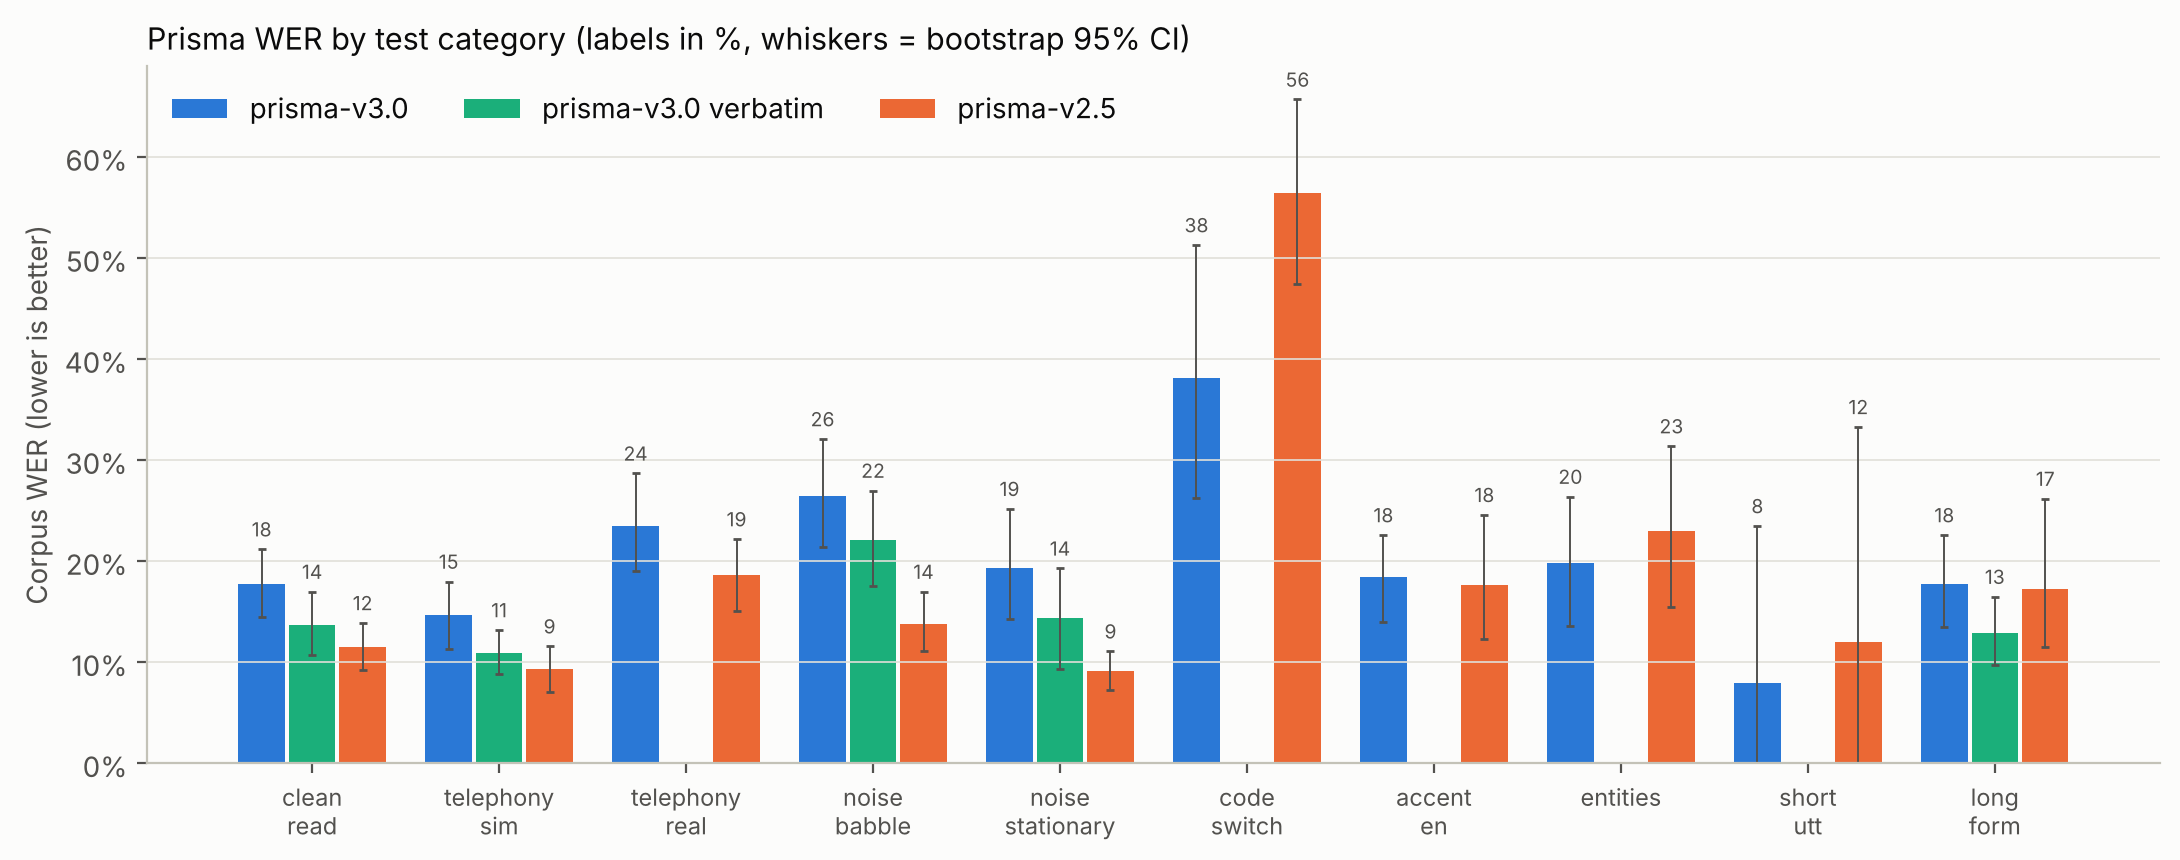

In [15]:
fig, ax = plt.subplots(figsize=(11, 4.4))
cats = [c for c in CAT_ORDER if c in set(head.category)]
xpos, w = np.arange(len(cats)), 0.27
for k, run in enumerate(RUN_ORDER):
    h = head[head.run == run].set_index("category").reindex(cats)
    ci = h["WER 95% CI"].fillna("nan%–nan%").str.split("–", expand=True).apply(lambda c: c.str.rstrip("%").astype(float) / 100)
    xs_ = xpos + (k - 1) * w
    ax.bar(xs_, h.WER, w * 0.92, color=RUN_COLOR[run], label=run,
           yerr=np.array([h.WER - ci[0], ci[1] - h.WER]), error_kw=dict(ecolor=INK2, lw=0.7, capsize=1.5))
    for x_, v, top_ in zip(xs_, h.WER, ci[1]):
        if pd.notna(v):
            ax.text(x_, (top_ if pd.notna(top_) else v) + 0.008, f"{v * 100:.0f}", ha="center", va="bottom", fontsize=7, color=INK2)
ax.set_xticks(xpos, [c.replace("_", "\n") for c in cats], fontsize=8.5)
ax.set_ylabel("Corpus WER (lower is better)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Prisma WER by test category (labels in %, whiskers = bootstrap 95% CI)", loc="left", fontsize=11)
ax.legend(loc="upper left", ncols=3)
ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIG / "wer_by_category.png", dpi=160); plt.show()

### 5.4 Noise: how fast does accuracy fall?
Same 20 Hindi sentences at every point, so the curve shows only the effect of noise.

Corpus WER on the same 20 Hindi sentences:


run,prisma-v3.0,prisma-v3.0 verbatim,prisma-v2.5
condition,,,
clean,15.2%,9.0%,8.0%
babble 20 dB,15.0%,9.2%,8.4%
babble 10 dB,16.8%,12.2%,9.2%
babble 5 dB,24.8%,19.6%,10.8%
babble 0 dB,49.5%,47.5%,26.9%
pink 5 dB,19.4%,14.4%,9.2%


How each configuration fails: deletions (goes quiet) vs insertions (adds words), per reference word


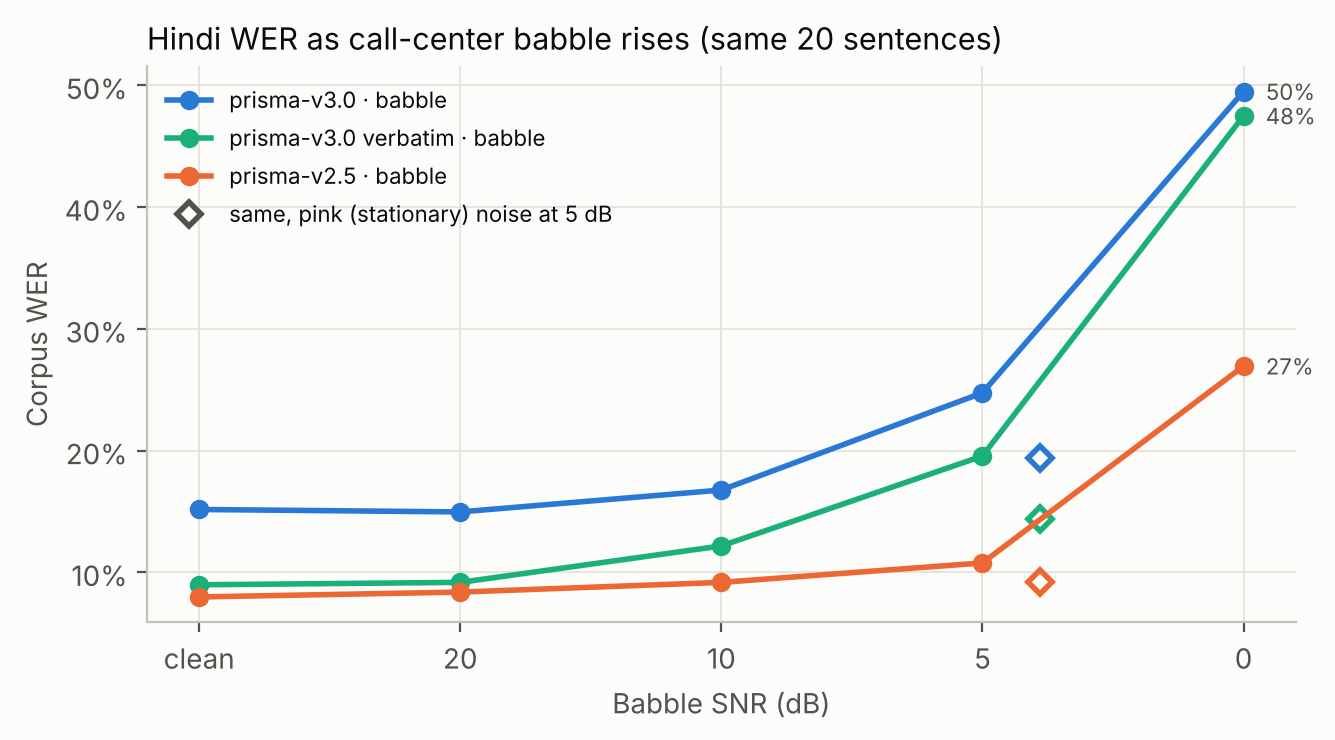

At 0 dB, two sentences side by side:


run,prisma-v3.0,prisma-v3.0 verbatim,prisma-v2.5
reference,,,
उनका काम ऐसी गुणवत्ता और विस्तार के पहचान का है कि वह टिकट संग्रहकर्ताओं के बीच बहुत कम घरेलू नामों में से एक है कुछ उनके काम को अकेले बटोरने में माहिर हैं,"उनका काम ऐसी गुणवत्ता और विस्तार में पहचान का है कि वह। क्रिकेट संग्रहकर्ताओं के लिए Hong Kong घरेलू नाम और भी हैं, ...","उनका काम ऐसी गुणवत्ता और विस्तार के लिहाज से काम है कि वह। क्रिकेट संग्रहकर्ताओं के लिए ओंगकॉम घरेलू नाम और भी हैं, ...",उनका काम ऐसी गुणवत्ता और विस्तार के पहचान की वह टिकट संग्रहकर्ताओं के बहुत कम घरेलू कामों में से एक है कुछ उनके काम ...
कैलिफोर्निया के गवर्नर अर्नोल्ड श्वार्ज़नेगर ने कानून में एक बिल पर हस्ताक्षर किए जो नाबालिगों को हिंसक वीडियो गेम उन्हें बेचने या किराए पर देने से प्रतिबंध लगाता है,"कैलिफ़र्निया के governor अल्नरड सजनगर Jewell कानून में एक bill पारित। किसान चरखे जो कर रहे हैं, नाबले उद्योग के लिए ...","कैलिफ़र्निया के गवर्नर अल्नरट सजनगरजू ने कानून में एक बिल पारित। किसान चरखे जो कर रहे हैं, नाबले उद्योग के लिए उपयोग...",कैलिफोर्निया के गवर्नर अर्नोल्ड शर्ज्नेगर ने कानून में एक बिल पर हस्ताक्षर किए जो नाबालिग या किराए पर देने प्रतिबंध ...


In [16]:
base20 = set(manifest[manifest.category == "noise_babble"].base_id)
COND = ["clean", "babble 20 dB", "babble 10 dB", "babble 5 dB", "babble 0 dB", "pink 5 dB"]
ladder = []
for run in RUN_ORDER:
    r_ = scored[scored.run == run]
    sets = {"clean": r_[r_.clip_id.isin(base20)]}
    sets.update({f"babble {s} dB": r_[(r_.noise_type == "babble") & (r_.snr_db == s)] for s in (20, 10, 5, 0)})
    sets["pink 5 dB"] = r_[r_.noise_type == "pink"]
    for cond, g in sets.items():
        ladder.append(dict(run=run, condition=cond, clips=len(g), WER=corpus(g), deletion_rate=corpus(g, "D"),
                           insertion_rate=corpus(g, "I"), substitution_rate=corpus(g, "S")))
ladder = pd.DataFrame(ladder)
print("Corpus WER on the same 20 Hindi sentences:")
display(ladder.pivot(index="condition", columns="run", values="WER").reindex(COND)[RUN_ORDER].style.format("{:.1%}"))
print("How each configuration fails: deletions (goes quiet) vs insertions (adds words), per reference word")
display(ladder[ladder.condition.isin(["babble 5 dB", "babble 0 dB"])]
        .pivot(index="run", columns="condition", values=["deletion_rate", "insertion_rate"]).reindex(RUN_ORDER).style.format("{:.1%}"))

fig, ax = plt.subplots(figsize=(6.8, 3.8))
xpos5 = np.arange(5)
for run in RUN_ORDER:
    d = ladder[ladder.run == run].set_index("condition")
    ax.plot(xpos5, d.loc[COND[:5], "WER"], marker="o", ms=6, lw=2, color=RUN_COLOR[run], label=f"{run} · babble")
    ax.plot([3.22], [d.loc["pink 5 dB", "WER"]], marker="D", ms=6, color=RUN_COLOR[run], ls="none", mfc="#fcfcfb", mew=2)
    ax.annotate(f"{d.loc['babble 0 dB', 'WER']:.0%}", (4, d.loc["babble 0 dB", "WER"]), textcoords="offset points",
                xytext=(8, -3), fontsize=8, color=INK2)
ax.plot([], [], marker="D", ms=6, color=INK2, ls="none", mfc="#fcfcfb", mew=2, label="same, pink (stationary) noise at 5 dB")
ax.set_xticks(xpos5, ["clean", "20", "10", "5", "0"])
ax.set_xlabel("Babble SNR (dB)"); ax.set_ylabel("Corpus WER")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Hindi WER as call-center babble rises (same 20 sentences)", loc="left", fontsize=11)
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "noise_ladder.png", dpi=160); plt.show()

print("At 0 dB, two sentences side by side:")
ex0 = scored[(scored.noise_type == "babble") & (scored.snr_db == 0) & scored.run.isin(RUN_ORDER)]
top_ins = ex0[ex0.run == "prisma-v3.0"].sort_values("I", ascending=False).clip_id.head(2)
display(ex0[ex0.clip_id.isin(top_ins)].pivot_table(index="reference", columns="run", values="hypothesis", aggfunc="first")[RUN_ORDER])

### 5.5 Telephony: clean vs simulated phone line vs real rural calls

In [17]:
tel = []
for run in RUN_ORDER:
    r_ = scored[scored.run == run]
    pair = r_[r_.category == "telephony_sim"].merge(r_[r_.category == "clean_read"][["clip_id", "wer"]],
                                                    left_on="base_id", right_on="clip_id", suffixes=("", "_clean"))
    tel += [dict(run=run, set="FLEURS clean 16 kHz (same 30 clips)", WER=corpus(r_[r_.clip_id.isin(set(pair.base_id))]),
                 CER=corpus(r_[r_.clip_id.isin(set(pair.base_id))], "cedits", "Nc")),
            dict(run=run, set="Same clips via G.711 8 kHz", WER=corpus(r_[r_.category == "telephony_sim"]),
                 CER=corpus(r_[r_.category == "telephony_sim"], "cedits", "Nc"),
                 clips_worse=int((pair.wer > pair.wer_clean + 1e-9).sum()), clips_better=int((pair.wer < pair.wer_clean - 1e-9).sum()))]
    if run in main_runs:
        g = r_[r_.category == "telephony_real"]
        tel.append(dict(run=run, set="GramVaani real rural calls 8 kHz", WER=corpus(g), CER=corpus(g, "cedits", "Nc")))
display(pd.DataFrame(tel).style.format({"WER": "{:.1%}", "CER": "{:.1%}", "clips_worse": "{:.0f}", "clips_better": "{:.0f}"}, na_rep="").hide(axis="index"))

gv = scored[(scored.category == "telephony_real") & scored.run.isin(main_runs)].copy()
gv["accent"] = gv.accent.replace({"nan": "unlabelled", "NA": "unlabelled", "": "unlabelled"})
print("GramVaani by labelled accent (small groups, read as directional only):")
display(summarize(gv, ["accent", "run"]).sort_values(["run", "clips"], ascending=[False, False])[["accent", "run", "clips", "WER", "CER"]]
        .style.format(pct(["WER", "CER"])).hide(axis="index"))

run,set,WER,CER,clips_worse,clips_better
prisma-v3.0,FLEURS clean 16 kHz (same 30 clips),14.7%,12.4%,,
prisma-v3.0,Same clips via G.711 8 kHz,14.7%,12.7%,5,3
prisma-v3.0,GramVaani real rural calls 8 kHz,23.5%,10.4%,,
prisma-v3.0 verbatim,FLEURS clean 16 kHz (same 30 clips),10.8%,4.1%,,
prisma-v3.0 verbatim,Same clips via G.711 8 kHz,10.9%,4.6%,7,4
prisma-v2.5,FLEURS clean 16 kHz (same 30 clips),9.6%,3.0%,,
prisma-v2.5,Same clips via G.711 8 kHz,9.3%,2.8%,2,5
prisma-v2.5,GramVaani real rural calls 8 kHz,18.7%,9.6%,,


GramVaani by labelled accent (small groups, read as directional only):


accent,run,clips,WER,CER
Accent_unknown,prisma-v3.0,13,16.6%,7.6%
unlabelled,prisma-v3.0,9,29.3%,13.0%
Bihari,prisma-v3.0,8,26.9%,11.6%
Accent_unknown,prisma-v2.5,13,14.8%,8.6%
unlabelled,prisma-v2.5,9,21.1%,10.9%
Bihari,prisma-v2.5,8,21.5%,9.3%


### 5.6 Languages and accents

In [18]:
lang_tbl = summarize(scored[scored.run.isin(main_runs) & scored.category.isin(["clean_read", "accent_en"])], ["category", "subcat", "run"])
display(lang_tbl[["category", "subcat", "run", "clips", "WER", "WER lenient", "CER"]].style.format(pct(["WER", "WER lenient", "CER"])).hide(axis="index"))

category,subcat,run,clips,WER,WER lenient,CER
clean_read,hi,prisma-v3.0,30,14.7%,13.2%,12.4%
clean_read,ta,prisma-v3.0,20,24.9%,24.9%,9.6%
accent_en,indian,prisma-v3.0,18,20.8%,20.8%,12.6%
accent_en,us,prisma-v3.0,10,15.2%,15.2%,10.1%
clean_read,hi,prisma-v2.5,30,9.6%,6.7%,3.0%
clean_read,ta,prisma-v2.5,20,15.9%,15.9%,4.3%
accent_en,indian,prisma-v2.5,18,20.8%,20.8%,14.8%
accent_en,us,prisma-v2.5,10,13.5%,13.5%,9.7%


### 5.7 Script choice: how much "error" is Latin vs native spelling?
Indian transcripts disagree on how to write English words. FLEURS and GramVaani write them in native script
(`फ़ोटोग्राफ़र`), MUCS mostly keeps them in Latin (`impress`). Prisma v3.0 with `transcribe` or `codemix` keeps
English words in Latin, as its docs say. When the two conventions differ, WER counts an error even if the word was heard right.

Substitutions are split into **cross-script** (one side Latin, the other an Indic script) and the rest.
"WER without cross-script" treats every cross-script substitution as correct, so it is an optimistic bound on recognition error.
It also forgives Latin words that are simply wrong (`स्फिंक्स` heard as `swings`), so it flatters v3.0. The `prisma-v3.0 verbatim`
run is the cleaner like-for-like comparison with v2.5.

In [19]:
LAT, IND = re.compile(r"[a-z]"), re.compile(r"[ऀ-෿]")


def is_cross(a, b):
    return bool((LAT.search(a) and IND.search(b)) or (IND.search(a) and LAT.search(b)))


xs_rows = []
for r in scored.itertuples():
    xs_rows.append(dict(category=r.category, run=r.run, N=r.N, edits=r.edits,
                        cross=sum(1 for op, a, b in r.ops if op == "S" and is_cross(a, b)),
                        lat_hyp=sum(bool(LAT.search(w)) for w in normalize(r.hypothesis).split()),
                        lat_ref=sum(bool(LAT.search(w)) for w in normalize(r.reference).split())))
xs = pd.DataFrame(xs_rows).groupby(["category", "run"], sort=False).sum()
xs["WER"] = xs.edits / xs.N
xs["cross-script share of edits"] = xs.cross / xs.edits
xs["WER without cross-script"] = (xs.edits - xs.cross) / xs.N
xs["Latin words hyp / ref"] = xs.lat_hyp / xs.lat_ref.replace(0, np.nan)
xs = xs.reset_index()
xs["category"] = pd.Categorical(xs.category, CAT_ORDER, ordered=True)
xs["run"] = pd.Categorical(xs.run, list(RUNS), ordered=True)
display(xs[xs.category.isin(CAT_ORDER) & (xs.category != "entities")]
        .sort_values(["category", "run"])[["category", "run", "WER", "cross-script share of edits", "WER without cross-script", "Latin words hyp / ref"]]
        .style.format({"WER": "{:.1%}", "cross-script share of edits": "{:.0%}", "WER without cross-script": "{:.1%}", "Latin words hyp / ref": "{:.2f}"}, na_rep="")
        .hide(axis="index"))

category,run,WER,cross-script share of edits,WER without cross-script,Latin words hyp / ref
clean_read,prisma-v3.0,17.8%,36%,11.3%,
clean_read,prisma-v2.5,11.5%,1%,11.4%,
clean_read,prisma-v3.0 verbatim,13.7%,0%,13.7%,
telephony_sim,prisma-v3.0,14.7%,46%,7.9%,
telephony_sim,prisma-v2.5,9.3%,1%,9.2%,
telephony_sim,prisma-v3.0 verbatim,10.9%,0%,10.9%,
telephony_real,prisma-v3.0,23.5%,0%,23.5%,
telephony_real,prisma-v2.5,18.7%,0%,18.7%,
noise_babble,prisma-v3.0,26.5%,33%,17.8%,
noise_babble,prisma-v2.5,13.8%,2%,13.6%,


**Code-switching in detail.** MUCS segment times come from subtitles, so some clips start late, end early or
carry speech the reference does not mention. Its references also contain glued tokens (`इनबॉक्सinbox`,
`sevenreasonstoadoptfossodt`). Two companion scores help read past that noise. They are applied identically to both models:

* **Edge-trimmed WER** ignores runs of deletions and insertions at the very start and end of each alignment (boundary noise).
  It also forgives genuine edge errors, so it is a lower bound.
* The **synthetic** subset has exact references, so it is the cleaner read on code-switching itself.

In [20]:
def edge_trim_edits(ops):
    kinds = [o for o, _, _ in ops]
    a, b = 0, len(kinds)
    while a < b and kinds[a] in "DI":
        a += 1
    while b > a and kinds[b - 1] in "DI":
        b -= 1
    return sum(o != "C" for o in kinds[a:b])


cs = scored[scored.category == "code_switch"].copy()
cs["edge_trim"] = cs.ops.apply(edge_trim_edits)
cs["cross"] = cs.ops.apply(lambda ops: sum(1 for o, a, b in ops if o == "S" and is_cross(a, b)))
cs_tbl = cs.groupby(["subcat", "run"]).agg(clips=("clip_id", "size"), N=("N", "sum"), edits=("edits", "sum"),
                                            trim=("edge_trim", "sum"), cross=("cross", "sum"), D=("D", "sum"), I=("I", "sum"))
cs_tbl["WER"] = cs_tbl.edits / cs_tbl.N
cs_tbl["edge-trimmed WER"] = cs_tbl.trim / cs_tbl.N
cs_tbl["WER without cross-script"] = (cs_tbl.edits - cs_tbl.cross) / cs_tbl.N
cs_tbl["edge-trimmed, no cross-script"] = (cs_tbl.trim - cs_tbl.cross) / cs_tbl.N
display(cs_tbl[["clips", "WER", "edge-trimmed WER", "WER without cross-script", "edge-trimmed, no cross-script"]]
        .style.format({c: "{:.1%}" for c in ["WER", "edge-trimmed WER", "WER without cross-script", "edge-trimmed, no cross-script"]}))
print("Synthetic Hinglish, side by side:")
display(res[(res.category == "code_switch") & (res.subcat == "synthetic")]
        .pivot_table(index="reference", columns="run", values="hypothesis", aggfunc="first"))

Synthetic Hinglish, side by side:


run,prisma-v2.5,prisma-v3.0
reference,,
"Branch manager से बात करवा दीजिए, यह urgent है।","ब्रांच मैनेजर से बात करवा दीजिए, यह अर्जेंट है।","branch manager से बात करवा दीजिए, यह urgent है।"
"Delivery address change करना है, क्या यह possible है?","डिलीवरी एड्रेस चेंज करना है, क्या यह पॉसिबल है?","डिलीवरी एड्रेस चेंज करना है, क्या यह पॉसिबल है?"
Insurance claim के लिए सारे documents upload कर दीजिए।,इंश्योरेंस क्लेम के लिए सारे डॉक्यूमेंट्स अपलोड कर दीजिए।,इन्श्योरेंस क्लेम के लिए सारे documents upload कर दीजिए।
Network issue की वजह से call drop हो गया था।,नेटवर्क इश्यू की वजह से कॉल ड्रॉप हो गया था।,नेटवर्क इश्यू की वजह से कॉल ड्रॉप हो गया था।
"Sir, आपका card delivery के लिए dispatch हो चुका है।",सर आपका कार्ड डिलीवरी के लिए डिस्पैच हो चुका है।,"सर, आपका कार्ड डिलीवरी के लिए डिस्पैच हो चुका है।"
आप app में login करके password reset कर सकते हैं।,आप ऐप में लॉगइन करके पासवर्ड रिसेट कर सकते हैं।,आप app में login करके password reset कर सकते हैं।
"आपका refund initiate हो गया है, bank account में credit हो जाएगा।","आपका रिफंड इनिशिएट हो गया है, बैंक अकाउंट में क्रेडिट हो जाएगा।","आपका refund initiate हो गया है, बैंक account में credit हो जाएगा।"
"आपकी request हमने register कर ली है, जल्दी ही update मिलेगा।","आपकी क्वेस्ट हमने रजिस्टर कर ली है, जल्दी ही अपडेट मिलेगा।","आपकी quiz हमने register कर ली है, जल्दी ही update मिलेगा।"
"मुझे अपनी policy cancel करनी है, process क्या है?","मुझे अपनी पॉलिसी कैंसिल करनी है, प्रोसेस क्या है?","मुझे अपनी policy cancel करनी है, process क्या है?"


**Format ablation on the clean set.** Same 50 clips, three configurations. `verbatim` fixes the loanword script
but spells numbers out, which hurts on the sentences whose references contain digits.

In [21]:
abl = scored[(scored.category == "clean_read") & scored.run.isin(["prisma-v3.0", "prisma-v3.0 verbatim", "prisma-v2.5"])]
abl_tbl = summarize(abl, ["subcat", "has_digits", "run"])[["subcat", "has_digits", "run", "clips", "WER", "WER lenient", "CER"]]
display(abl_tbl.sort_values(["subcat", "has_digits", "run"]).style.format(pct(["WER", "WER lenient", "CER"])).hide(axis="index"))
display(summarize(abl, ["subcat", "run"])[["subcat", "run", "clips", "WER", "CER"]].style.format(pct(["WER", "CER"])).hide(axis="index"))

subcat,has_digits,run,clips,WER,WER lenient,CER
hi,False,prisma-v2.5,27,9.4%,6.4%,2.6%
hi,False,prisma-v3.0,27,15.3%,13.7%,13.4%
hi,False,prisma-v3.0 verbatim,27,10.5%,8.2%,3.3%
hi,True,prisma-v2.5,3,10.7%,8.9%,5.1%
hi,True,prisma-v3.0,3,10.7%,10.7%,5.9%
hi,True,prisma-v3.0 verbatim,3,12.5%,12.5%,8.7%
ta,False,prisma-v2.5,15,14.0%,14.0%,3.1%
ta,False,prisma-v3.0,15,23.1%,23.1%,10.0%
ta,False,prisma-v3.0 verbatim,15,15.7%,15.7%,3.4%
ta,True,prisma-v2.5,5,20.9%,20.9%,7.6%


subcat,run,clips,WER,CER
hi,prisma-v3.0,30,14.7%,12.4%
ta,prisma-v3.0,20,24.9%,9.6%
hi,prisma-v2.5,30,9.6%,3.0%
ta,prisma-v2.5,20,15.9%,4.3%
hi,prisma-v3.0 verbatim,30,10.8%,4.1%
ta,prisma-v3.0 verbatim,20,20.4%,5.4%


### 5.8 Numbers and banking entities
Entity accuracy asks the question a bank cares about: did the amount, date or ID come back exactly right?
Digit separators inside numbers are removed before matching (`4520 3398 1176` = `452033981176`).

In [22]:
def norm_entity_text(s):
    s = normalize(s)
    for _ in range(3):
        s = re.sub(r"(?<=\d)[\s\-](?=\d)", "", s)
    return f" {s} "


MONTH = re.compile(r"jan|feb|mar|apr|may|jun|jul|aug|sep|oct|nov|dec|जनवरी|फ़?फरवरी|मार्च|अप्रैल|मई|जून|जुलाई|अगस्त|सितंबर|अक्टूबर|नवंबर|दिसंबर")


def entity_kind(form):
    if MONTH.search(form) or ":" in form:
        return "date / time"
    if re.fullmatch(r"[\d.]+", form):
        return "amount / number"
    return "alphanumeric code" if re.search(r"\d", form) else "banking term"


ent_rows = []
for r in res[res.category == "entities"].itertuples():
    ents = json.loads(manifest.set_index("clip_id").loc[r.clip_id, "entities"])
    h = norm_entity_text(r.hypothesis)
    for forms in ents:
        ok = any(f" {norm_entity_text(f).strip()} " in h for f in forms)
        kind = entity_kind(forms[0])
        ent_rows.append(dict(run=r.run, clip_id=r.clip_id, subcat=r.subcat, entity=forms[0], kind=kind, correct=ok, hypothesis=r.hypothesis))
ents = pd.DataFrame(ent_rows)
ent_tbl = ents.pivot_table(index=["kind"], columns="run", values="correct", aggfunc="mean")
ent_tbl.loc["all entities"] = ents.groupby("run").correct.mean()
display(ent_tbl[[r for r in RUNS if r in ent_tbl.columns]].style.format("{:.0%}"))
display(ents.pivot_table(index="subcat", columns="run", values="correct", aggfunc="mean")[[r for r in RUNS if r in ent_tbl.columns]].style.format("{:.0%}"))
display(summarize(res[res.category == "entities"], "run")[["run", "clips", "WER", "CER"]].style.format(pct(["WER", "CER"])).hide(axis="index"))
print("Every entity miss:")
display(ents[~ents.correct][["run", "clip_id", "entity", "hypothesis"]].sort_values(["clip_id", "run"]))

run,prisma-v3.0,prisma-v2.5,prisma-v3.0+keyterms
kind,,,
alphanumeric code,0%,100%,100%
amount / number,100%,95%,100%
banking term,100%,95%,100%
date / time,100%,100%,100%
all entities,98%,96%,100%


run,prisma-v3.0,prisma-v2.5,prisma-v3.0+keyterms
subcat,,,
english,91%,91%,100%
hindi,100%,100%,100%
hinglish,100%,93%,100%


run,clips,WER,CER
prisma-v3.0,24,19.8%,19.2%
prisma-v2.5,24,23.0%,19.0%
prisma-v3.0+keyterms,24,18.9%,20.0%


Every entity miss:


,run,clip_id,entity,hypothesis
81,prisma-v2.5,ent_cm_02,transfer,"मैंने ऑलरेडी ₹5,000 ट्रांसफ़र कर दिए हैं आप चेक कर लीजिए।"
24,prisma-v3.0,ent_en_02,hdfc0001234,Please share the IFSC code 0001234 for the NEFT transfer.
77,prisma-v2.5,ent_en_06,18002661234,call our toll free number 180026612344 help


In [23]:
print("Real speech: FLEURS Hindi/Tamil sentences with digits vs without (format=transcribe)")
cr = scored[scored.run.isin(main_runs) & (scored.category == "clean_read")]
display(summarize(cr, ["has_digits", "run"])[["has_digits", "run", "clips", "WER", "WER lenient", "CER"]].style.format(pct(["WER", "WER lenient", "CER"])).hide(axis="index"))

Real speech: FLEURS Hindi/Tamil sentences with digits vs without (format=transcribe)


has_digits,run,clips,WER,WER lenient,CER
False,prisma-v3.0,42,17.4%,16.2%,12.1%
True,prisma-v3.0,8,19.2%,19.2%,7.5%
False,prisma-v2.5,42,10.7%,8.4%,2.8%
True,prisma-v2.5,8,15.3%,14.3%,6.6%


### 5.9 Short replies and long turns

In [24]:
print("FLEURS Hindi only (same speakers and style), by clip length. Deletion rate = deleted words / reference words.")
dur = scored[scored.run.isin(RUN_ORDER) & (((scored.category == "clean_read") & (scored.subcat == "hi")) | (scored.category == "long_form"))].copy()
dur["length"] = pd.cut(dur.duration_s, [0, 8, 15, 21.9, 30.1], labels=["4–8 s", "8–15 s", "15–22 s", "22–30 s (joined)"])
dl = summarize(dur, ["length", "run"])
dl["run"] = pd.Categorical(dl.run, RUN_ORDER, ordered=True)
display(dl.sort_values(["length", "run"])[["length", "run", "clips", "WER", "CER", "deletion rate"]]
        .style.format(pct(["WER", "CER", "deletion rate"])).hide(axis="index"))


def trailing_deletions(ops):
    k = 0
    for o, _, _ in reversed(ops):
        if o != "D":
            break
        k += 1
    return k


tail = scored[scored.run.isin(RUN_ORDER) & scored.category.isin(["long_form", "clean_read", "telephony_real", "telephony_sim"])].copy()
tail["tail_drop"] = tail.ops.apply(trailing_deletions)
print("Clips whose last 5+ reference words are missing from the transcript (dropped endings):")
display(tail.pivot_table(index="category", columns="run", values="tail_drop", aggfunc=lambda s: f"{(s >= 5).sum()}/{len(s)}")
        .reindex(columns=RUN_ORDER))
su = res[(res.category == "short_utt") & res.run.isin(main_runs)]
display(summarize(su, ["subcat", "run"])[["subcat", "run", "clips", "WER", "WER lenient"]].style.format(pct(["WER", "WER lenient"])).hide(axis="index"))
print("Short replies, side by side:")
display(su.pivot_table(index=["clip_id", "reference"], columns="run", values="hypothesis", aggfunc="first"))
print("Truncated responses:", int(res.truncated.sum()))

FLEURS Hindi only (same speakers and style), by clip length. Deletion rate = deleted words / reference words.


length,run,clips,WER,CER,deletion rate
15–22 s,prisma-v3.0,9,12.6%,9.7%,0.6%
15–22 s,prisma-v3.0 verbatim,9,9.4%,4.2%,0.6%
15–22 s,prisma-v2.5,9,9.7%,3.9%,0.6%
22–30 s (joined),prisma-v3.0,11,18.9%,16.6%,2.7%
22–30 s (joined),prisma-v3.0 verbatim,11,13.8%,6.6%,2.7%
22–30 s (joined),prisma-v2.5,11,16.9%,9.6%,6.8%
4–8 s,prisma-v3.0,6,11.8%,8.1%,0.0%
4–8 s,prisma-v3.0 verbatim,6,9.4%,1.7%,0.0%
4–8 s,prisma-v2.5,6,7.1%,2.4%,0.0%
8–15 s,prisma-v3.0,14,14.9%,13.2%,0.6%


Clips whose last 5+ reference words are missing from the transcript (dropped endings):


run,prisma-v3.0,prisma-v3.0 verbatim,prisma-v2.5
category,,,
clean_read,0/50,0/50,0/50
long_form,0/10,0/10,1/10
telephony_real,0/30,NaN,1/30
telephony_sim,0/30,0/30,0/30


subcat,run,clips,WER,WER lenient
gramvaani,prisma-v3.0,4,14.3%,14.3%
synthetic,prisma-v3.0,10,5.6%,5.6%
gramvaani,prisma-v2.5,4,42.9%,42.9%
synthetic,prisma-v2.5,10,0.0%,0.0%


Short replies, side by side:


,run,prisma-v2.5,prisma-v3.0
clip_id,reference,,
gv_01-02334-02,धन्यवाद,धन्यवाद,धन्यवाद।
gv_01-07865-01,मानने,मान नहीं,माननीय।
gv_02-14755-01,धन्यवाद,धन्यवाद,धन्यवाद।
gv_02-16446-01,अपने टीम के साथ,अपने टीम के साथ मौजूद,अपने टीम के साथ।
short_01,हाँ,हाँ,हाँ।
short_02,नहीं,नहीं,नहीं
short_03,हाँ जी,हाँ जी,हाँ जी।
short_04,जी बोलिए,जी बोलिए,जी बोलिए।
short_05,ठीक है,ठीक है,ठीक है।


Truncated responses: 0


### 5.10 No-speech probes (hallucination)
The right output for every clip here is an empty string.

In [25]:
ns = res[(res.category == "no_speech") & res.run.isin(main_runs)]
display(ns.pivot_table(index="subcat", columns="run", values="hypothesis", aggfunc="first").fillna(""))
print(ns.groupby("run").apply(lambda g: f"{(g.hyp_words > 0).sum()}/{len(g)} probes produced text, {g.hyp_words.sum()} words in total",
                              include_groups=False).to_string())

run,prisma-v2.5,prisma-v3.0
subcat,,
babble_only_-25dBFS,एक हजार नौ सौ उनसठ के बाद मिश्री अखबार,एक हजार नौ सौ पैंसठ के बाद विदेशी कंपनियों ने बहुत छोटा बाजार भी हासिल।
hold_music,,
keyboard_clicks,,
mains_hum_50Hz,,
pink_noise_-30dBFS,,
ringback_tone,,
silence,,
white_noise_-45dBFS,,


run
prisma-v2.5     1/8 probes produced text, 9 words in total
prisma-v3.0    1/8 probes produced text, 15 words in total


### 5.11 Latency and real-time factor
`processing_time` is server compute. RTF = processing_time ÷ audio duration (below 1 means faster than real time).
One request at a time, so this is idle-load latency, not latency under concurrency.

,requests,server_p50_ms,server_p95_ms,e2e_p50_ms,e2e_p95_ms,rtf_p50,rtf_p95,client_wall_p50_ms
run,,,,,,,,
prisma-v2.5,336,153,252,195,357,0.017,0.044,908
prisma-v3.0,336,210,298,246,812,0.023,0.045,960


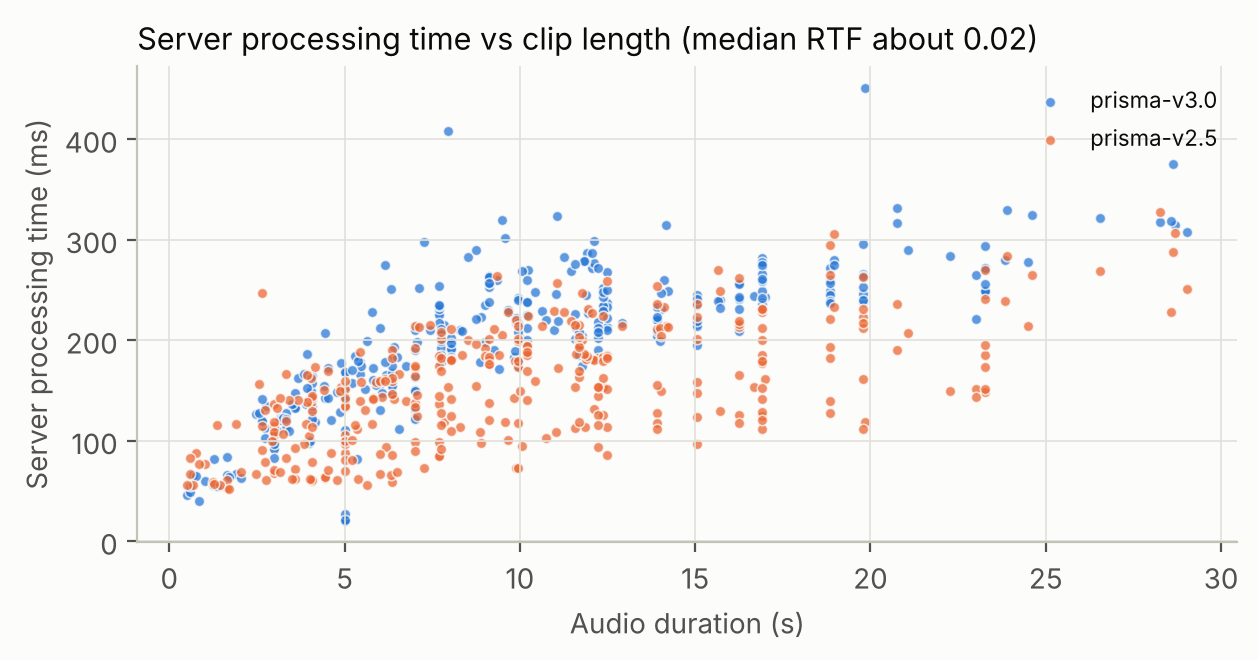

In [26]:
lat = res[res.run.isin(main_runs)].groupby("run").agg(
    requests=("clip_id", "size"),
    server_p50_ms=("processing_s", lambda s: 1000 * s.quantile(0.5)),
    server_p95_ms=("processing_s", lambda s: 1000 * s.quantile(0.95)),
    e2e_p50_ms=("e2e_s", lambda s: 1000 * s.quantile(0.5)),
    e2e_p95_ms=("e2e_s", lambda s: 1000 * s.quantile(0.95)),
    rtf_p50=("rtf", "median"), rtf_p95=("rtf", lambda s: s.quantile(0.95)),
    client_wall_p50_ms=("client_wall_s", lambda s: 1000 * s.quantile(0.5)))
display(lat.style.format("{:.0f}", subset=[c for c in lat.columns if c.endswith("ms")]).format("{:.3f}", subset=["rtf_p50", "rtf_p95"]))

fig, ax = plt.subplots(figsize=(6.4, 3.4))
for run, col in (("prisma-v3.0", C_V3), ("prisma-v2.5", C_V25)):
    d = res[res.run == run]
    ax.scatter(d.duration_s, 1000 * d.processing_s, s=14, color=col, alpha=0.75, label=run, edgecolors="#fcfcfb", linewidths=0.6)
ax.set_xlabel("Audio duration (s)"); ax.set_ylabel("Server processing time (ms)")
ax.set_title("Server processing time vs clip length (median RTF about 0.02)", loc="left", fontsize=11)
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "latency_vs_duration.png", dpi=160); plt.show()

## 6 · Error analysis
### 6.1 What kind of errors? (S / D / I mix per category, Prisma v3.0)

In [27]:
mix = scored[scored.run == "prisma-v3.0"].groupby("category")[["S", "D", "I", "edits", "N"]].sum()
mix = mix.reindex([c for c in CAT_ORDER if c in mix.index])
mix_pct = pd.DataFrame({"substitutions": mix.S / mix.edits, "deletions": mix.D / mix.edits, "insertions": mix.I / mix.edits,
                        "WER": mix.edits / mix.N})
display(mix_pct.style.format("{:.0%}"))

,substitutions,deletions,insertions,WER
category,,,,
clean_read,83%,5%,13%,18%
telephony_sim,88%,6%,6%,15%
telephony_real,71%,21%,8%,24%
noise_babble,74%,8%,18%,26%
noise_stationary,82%,8%,9%,19%
code_switch,46%,42%,12%,38%
accent_en,47%,45%,8%,18%
entities,65%,12%,23%,20%
short_utt,100%,0%,0%,8%


### 6.2 Most frequent word substitutions (Prisma v3.0, all real-speech categories)

In [28]:
subs = Counter()
for r in scored[(scored.run == "prisma-v3.0") & ~scored.category.isin(["entities", "short_utt"])].itertuples():
    subs.update((a, b) for op, a, b in r.ops if op == "S")
top = pd.DataFrame([(a, b, n) for (a, b), n in subs.most_common(25)], columns=["reference", "prisma-v3.0", "count"])
top["pattern"] = top.apply(lambda t: "same word, nukta/chandrabindu only" if normalize(t.reference, True) == normalize(t["prisma-v3.0"], True)
                           else ("script switch" if is_cross(t.reference, t["prisma-v3.0"]) else ""), axis=1)
top

,reference,prisma-v3.0,count,pattern
0,सिंगापुर,singapore,14,script switch
1,ओलंपिक,olympic,14,script switch
2,हैं,है,14,
3,डायनासोर,dinosaur,8,script switch
4,नेशनल,national,8,script switch
5,रिसॉर्ट,resort,7,script switch
6,फ़ोटोग्राफ़रों,photographers,7,script switch
7,रेक्स,rex,7,script switch
8,गवर्नर,governor,7,script switch
9,बिल,bill,7,script switch


### 6.3 Worst clips per category (Prisma v3.0)

In [29]:
worst = (scored[scored.run == "prisma-v3.0"].sort_values("wer", ascending=False).groupby("category").head(2)
         [["category", "clip_id", "wer", "reference", "hypothesis"]])
worst["category"] = pd.Categorical(worst.category, CAT_ORDER, ordered=True)
worst.sort_values(["category", "wer"], ascending=[True, False]).style.format({"wer": "{:.0%}"}).hide(axis="index")

category,clip_id,wer,reference,hypothesis
clean_read,fleurs_ta_746018015198125899,61%,அறிவியல் வல்லுனர்களால் பொதுவான மேட்டர்/பருப்பொருளில் ஏற்படுவது போலவே ஒரு டார்க் மேட்டர் மற்றொரு டார்க் மேட்டரை பாதிக்கிறது என்ற முடிவு செய்ய இயன்றது,"அறிவியல் வல்லுனர்களால் பொதுவான matter. பரப்பொருளில் ஏற்படுவது போலவே, ஒரு dark matter மற்றது dark matter-ஐ பார்க்கிறது என்று முடிவு செய்ய இயன்றனர்."
clean_read,fleurs_ta_10170056955437280049,57%,அந்தப் பாலம் செப்டெம்பர் 2017 இல் பிரேசிலிய சுங்கத்துறை சோதனைச் சாவடிகள் தயாரானதும் முழுவதுமாக செயல்படத் திட்டமிடப் பட்டுள்ளது,அந்த பாலம் September 2017-இல் பிரேசிலிய சுங்க துறை சோதனை சாவடிகள் தயாரானதும் முழுவதுமாக செயல்பட. திட்டமிடப்பட்டுள்ளது.
telephony_sim,fleurs_hi_5480881948821631080_g711,34%,कैलिफोर्निया के गवर्नर अर्नोल्ड श्वार्ज़नेगर ने कानून में एक बिल पर हस्ताक्षर किए जो नाबालिगों को हिंसक वीडियो गेम उन्हें बेचने या किराए पर देने से प्रतिबंध लगाता है,California के governor Arnold Schwarzenegger ने कानून में एक bill पर हस्ताक्षर। जो नाबालिगों के हिंसक video game उन्हें बेचने या किराए पर देने से प्रतिबंध लगाया है।
telephony_sim,fleurs_hi_11512325763784312342_g711,33%,भवनों की परेड जिसने हांगकांग की स्कायलाइन को चमचमाते बार चार्ट की तरह बनाया है उसने विक्टोरिया हार्बर के पानी की मौज़ूदगी को देखने लायक बनाया है,"भवनों की parade, जिसने Hong Kong की skyline को चमचमाते bar। chart की तरह बनाया है, उसने Victoria Harbour के पानी की मौजूदगी को देखने लायक बनाया है।"
telephony_real,gv_01-06170-02,69%,मधुबनी मोबाइल वाणी प्रखंड खुटौना से चंदू नमस्कार खुटौना समाजसेवी पुर्व प्रखंड अध्यक्ष संजय सोरान ने सरकार के रवैया पर दुःख जताते हुए कहा की राशन,"मातवाणी मोबाइल वाणी प्रखंड, पटौना ऐसी चंदू, नमस्कार। पटौना समाज से भी पूर्व प्रखंड अध्यक्ष राम ने सरकार की रब्बैया पर दुख व्यक्त करते हुए कहा। कहा कि राष्ट्रपति।"
telephony_real,gv_01-02717-01,42%,विश्व की विश्व भर के समुंद्री प्रजातियाँ जैसे समुंद्री पक्षियां कीवर्ड मछलियाँ,"विश्व की विश्व भर की समुद्री प्रजातियाँ, जैसे समुद्री पक्षियाँ, सीवार्ड मछलियाँ।"
noise_babble,fleurs_hi_5480881948821631080_babble0dB,100%,कैलिफोर्निया के गवर्नर अर्नोल्ड श्वार्ज़नेगर ने कानून में एक बिल पर हस्ताक्षर किए जो नाबालिगों को हिंसक वीडियो गेम उन्हें बेचने या किराए पर देने से प्रतिबंध लगाता है,"कैलिफ़र्निया के governor अल्नरड सजनगर Jewell कानून में एक bill पारित। किसान चरखे जो कर रहे हैं, नाबले उद्योग के लिए उपयोग कर रहे हैं। या किराए पर रहने के लिए प्रतिबंध लगाया गया था, 3 साल तक।"
noise_babble,fleurs_hi_10980788482676060439_babble0dB,100%,उन्होंने अफवाहों को राजनीतिक बकवास और मूर्खतापूर्ण कहा,इसको भुनाने का अवसर राजनीतिक बपस और मौका मौका है।
noise_stationary,fleurs_hi_5480881948821631080_pink5dB,48%,कैलिफोर्निया के गवर्नर अर्नोल्ड श्वार्ज़नेगर ने कानून में एक बिल पर हस्ताक्षर किए जो नाबालिगों को हिंसक वीडियो गेम उन्हें बेचने या किराए पर देने से प्रतिबंध लगाता है,"California के governor Arnold Schwarzenegger ने कानून में एक bill पर हस्ताक्षर। culture किए, जो नाबालिगों के हिंसक प्रयोग में उन्हें बेच में किया। किराया पर देने से प्रतिबंध लगाया है।"
noise_stationary,fleurs_hi_11512325763784312342_pink5dB,37%,भवनों की परेड जिसने हांगकांग की स्कायलाइन को चमचमाते बार चार्ट की तरह बनाया है उसने विक्टोरिया हार्बर के पानी की मौज़ूदगी को देखने लायक बनाया है,"भवनों की parade, जिसमें Hong Kong की skyline को चमचमाते bar। chart की तरह बनाया है, उसने Victoria Harbour के पानी की मौजूदगी को देखने लायक बनाया है।"


### 6.4 Where v2.5 and v3.0 disagree most

In [30]:
pv = scored[scored.run.isin(main_runs)].pivot_table(index=["category", "clip_id"], columns="run", values="wer")
pv["v3 minus v2.5"] = pv["prisma-v3.0"] - pv["prisma-v2.5"]
print("Clips where v3.0 is better / worse / tied:",
      int((pv["v3 minus v2.5"] < 0).sum()), "/", int((pv["v3 minus v2.5"] > 0).sum()), "/", int((pv["v3 minus v2.5"] == 0).sum()))
pv.groupby(level="category").agg(v3_better=("v3 minus v2.5", lambda s: int((s < 0).sum())),
                                 v3_worse=("v3 minus v2.5", lambda s: int((s > 0).sum())),
                                 mean_delta=("v3 minus v2.5", "mean")).reindex(CAT_ORDER).style.format({"mean_delta": "{:+.1%}"})

Clips where v3.0 is better / worse / tied: 89 / 168 / 71


,v3_better,v3_worse,mean_delta
category,,,
clean_read,8,31,+6.8%
telephony_sim,6,16,+5.2%
telephony_real,5,16,+4.2%
noise_babble,13,61,+12.1%
noise_stationary,2,15,+9.4%
code_switch,30,5,-23.1%
accent_en,13,12,-3.8%
entities,8,6,-2.8%
short_utt,2,1,-1.8%


## 7 · Findings and recommendation

Numbers below come from the run on 15 November 2026: 336 clips (56.9 minutes) and 886 API calls. Every number is in the tables above.

| Category | v3.0 (configured format) | v3.0 `verbatim` | v2.5 | Read it as |
|---|---|---|---|---|
| Clean read, Hindi + Tamil | 17.8% | 13.7% | 11.5% | v2.5 slightly ahead like for like |
| Same clips via G.711 8 kHz | 14.7% | 10.9% | 9.3% | phone channel costs nothing |
| Real rural phone calls (GramVaani) | 23.5% | | 18.7% | v2.5 ahead |
| Babble noise, 20 to 0 dB | 26.5% | 22.1% | 13.8% | v2.5 clearly ahead |
| Code-switched Hindi-English | 38.1% | | 56.4% | v3.0 ahead (formatting) |
| Indian-accented English | 18.4% | | 17.7% | tie |
| Banking entities, exact match | 97.8% (100% with keyterms) | | 95.7% | v3.0 ahead |
| Long turns, 22 to 30 s | 17.8% | 12.9% | 17.3% | v3.0 ahead like for like |

### Where Prisma is strong
* **The phone channel does not hurt it.** Pushing the same 30 Hindi clips through a 300–3400 Hz, 8 kHz G.711 channel left WER unchanged
  for every configuration (v2.5 9.6% to 9.3%, v3.0 verbatim 10.8% to 10.9%). This matches Gnani's focus on telephony audio.
* **It does not invent text from non-speech.** Silence, hiss, mains hum, ringback tone, hold music and keyboard clicks all returned an
  empty transcript on both models. Both did transcribe a quiet bed of background chatter, which is real speech, so a noisy floor can leak into a transcript.
* **Numbers come back as usable digits.** Lakh-grouped amounts, dates, phone and account numbers, OTPs and PIN codes were exact in
  45 of 46 entities on v3.0 and 44 of 46 on v2.5. Adding 12 domain keyterms on v3.0 fixed the one miss (`HDFC0001234` had lost `HDFC`), so 46 of 46.
* **Short replies are reliable.** The ten synthetic replies ("हाँ", "नहीं", "जी बोलिए", "बाद में कॉल कीजिए" and others) came back correct on both models,
  apart from one spelling variant on v3.0 (`हेलो` as `हैलो`).
* **It is fast.** Median server time is 153 ms (v2.5) and 210 ms (v3.0), p95 under 300 ms, a real-time factor near 0.02.
* **v3.0 handles long turns better.** v2.5 dropped the last sentence of one 24-second turn (25 words) and the end of one rural call. v3.0 dropped none.

### Where it breaks down
* **Heavy background speech, and v3.0 fails in a risky way.** At 5 dB babble, v3.0 reaches 24.8% WER (19.6% in verbatim) against 10.8% for v2.5.
  At 0 dB both collapse, but differently. v2.5 goes quiet (16% of reference words deleted, under 1% inserted). v3.0 writes fluent
  sentences that are not in the target speech (11% inserted). Examples: "पुलिस और army के जवान" in a sentence about stamp collectors, and
  "भारत माता की जय" in one about galaxy simulations. At 10 dB the two models insert at similar rates (1.6% and 1.2%).
  For a bank, an invented sentence is worse than a gap, because nothing downstream can tell it apart from real speech.
* **Real rural calls are hard for both.** GramVaani WER is 18.7% (v2.5) and 23.5% (v3.0). Place and person names fail most
  (`मधुबनी` heard as `मातवाणी`). Some of this is reference noise, since GramVaani transcripts have their own typos.
* **Tamil WER looks bad, but CER does not.** Tamil WER is 15.9% (v2.5) to 24.9% (v3.0) while CER is 4.3% to 9.6%. Most errors are
  suffix-level inside long words, so CER is the fairer measure for Dravidian languages.
* **v3.0 mixes scripts inside Hindi text.** With `transcribe`, English loanwords stay in Latin (`photographers`, `dinosaur`), month
  names come back in English (`15 January 2027`), and currency comes back as `रुपये` instead of `₹`. This is documented behaviour, but any
  downstream parser or keyword search has to expect it. It accounts for 36% of v3.0's errors on clean read speech.
* **`codemix` is not consistent.** On the clean Hinglish set, 3 of 12 sentences came back entirely in Devanagari, and one real
  mishearing appeared (`request` as `quiz`).
* **v2.5 corrupted one phone number.** It merged the next word into a toll-free number (`180026612344`), which would dial a wrong number.

### Reading the conflicting results
* **The raw overall number misleads.** Across everything, v2.5 scores 17.2% WER and v3.0 22.4%, which looks like a clear win for the older model.
  On the FLEURS-based sets, most of the gap is script convention, not hearing. Run in `verbatim`, v3.0 closes most of it (clean 13.7% vs 11.5%,
  phone channel 10.9% vs 9.3%, with overlapping confidence intervals). In babble noise the gap stays large (22.1% vs 13.8%), so that one is real.
* **The code-switching win is also about script.** v2.5 wrote every English word in Devanagari. If those cross-script substitutions are
  set aside, its WER on the clean Hinglish set drops to 0%. v2.5 heard the words fine. v3.0's advantage is that it writes English the way
  a downstream LLM or search index expects.
* **About a quarter of v2.5's remaining Hindi "errors" are spelling choices.** Folding nukta and chandrabindu variants cuts its
  WER from 9.3% to 6.7% on the phone-channel set. A native reader would accept both spellings.
* **MUCS references are noisy.** Its timestamps come from subtitles. After trimming boundary errors and setting script aside, the two models sit
  at 19.6% (v3.0) and 18.0% (v2.5), against raw scores of 43.9% and 61.4%.

### Recommendation for a contact-center customer
1. **Default to Prisma v3.0** when transcripts feed an LLM, intent model or analytics, when traffic is Hinglish-heavy, or when the goal
   is capturing amounts and IDs. Use `format=transcribe` with domain keyterms for entity capture, and `codemix` where numbers are not needed.
2. **Do not run v3.0 alone on noisy channels** such as field agents, speakerphone callers or busy floors. At 5 dB SNR and below it adds
   words that were never said. Either keep v2.5 for those queues, add noise suppression before ASR, or ask Gnani for a confidence score so low-confidence spans can be flagged.
   The REST response has no confidence field today.
3. **Guard money and IDs whichever model is used.** Read back amounts, account numbers and dates for confirmation, and validate formats
   (IFSC pattern, 10-digit mobile) before acting on them.
4. **Write the downstream parser for v3.0's mixed output**: Latin English words and month names inside Hindi, `रुपये` as well as `₹`.
5. **Pilot on the customer's own audio before go-live.** Re-run this notebook on 200 to 500 of their 8 kHz calls per language, with their real
   noise floor and entity types, and measure latency under their peak concurrency.

### Limitations
* Samples per category are small (10 to 80 clips). Bootstrap intervals are wide, so differences under about 3 points should be read as ties.
* Babble noise and the phone channel are simulated. Real call-center noise and codecs (AMR, Opus, packet loss) differ.
* Entity and short-reply probes use synthetic speech with clean, standard pronunciation. They test formatting and vocabulary, not acoustics.
* Latency was measured one request at a time from outside India. The account allows one active request, so concurrency was not tested.
  The streaming WebSocket API was not tested.
* Only 3 Indian-English speakers (EdAcc) and 4 real short GramVaani replies, so those results are directional.